# Periodogram, Bartlett and Welch: from the basics to the proofs

**Power spectral density estimation**

This notebook works through spectral estimation from the start, around one question:

> We have only $N$ samples of a random signal that goes on forever.
> How well can we tell how its power is spread over frequency?

The answer most people reach for first is the **periodogram**: take the FFT, square it, done.
It has a serious flaw that only shows up when you prove things about it, and **Bartlett's** and
**Welch's** methods are the fixes.

### What the notebook covers

| Part | Content |
|---|---|
| 1 | Signals, sampling, DTFT → DFT |
| 2 | Autocorrelation, PSD and the Wiener–Khinchin theorem |
| 3 | Proof that the periodogram is the DTFT of the biased ACF |
| 4 | Proofs of the bias (Fejér kernel) and the variance, which show the periodogram is *not* consistent |
| 5 | Spectral leakage, windows, resolution and dynamic range |
| 6 | Bartlett's method, with a proof that the variance drops by a factor of $K$ |
| 7 | Welch's method: normalization and the effect of overlap |
| 8 | Monte Carlo comparison of the three methods (bias, variance, MSE) |
| 9 | Practice with `scipy.signal`, checked against our own code |
| 10 | Summary and a decision table |

> Every proof is followed by a code cell that checks the result numerically.
> If a proof is hard to follow, look at the plot; if the plot is hard to believe, go back to the proof.

In [1]:
# ============================================================
# Setup: run this cell first
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sig
from scipy import stats

# ---- Colour palette shared by every plot in the notebook ------
# Each colour is tied to a meaning rather than to plotting order,
# so a colour means the same thing in every plot.
C_TRUE = "#0b0b0b"   # true PSD (reference), black dashed
C_PER  = "#2a78d6"   # Periodogram        (blue)
C_BAR  = "#eb6834"   # Bartlett           (orange)
C_WEL  = "#1baf7a"   # Welch              (teal)
C_ALT  = "#eda100"   # 4th series         (yellow)
C_MUTE = "#8a8a85"   # guide lines and background
GRID   = "#e3e2de"

# Blue ramp for an increasing quantity, such as N or K
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5",
         "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update({
    "font.family":        "DejaVu Sans",
    "figure.dpi":         110,
    "figure.figsize":     (11, 4),
    "savefig.bbox":       "tight",
    "axes.grid":          True,
    "grid.color":         GRID,
    "grid.linewidth":     0.8,
    "axes.edgecolor":     "#c9c8c3",
    "axes.labelcolor":    "#52514e",
    "text.color":         "#0b0b0b",
    "xtick.color":        "#52514e",
    "ytick.color":        "#52514e",
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "lines.linewidth":    1.6,
    "legend.frameon":     False,
    "axes.titleweight":   "bold",
    "axes.titlesize":     11,
    "font.size":          9.5,
})

rng = np.random.default_rng(2026)   # fixed seed, so results are reproducible

print("Ready: numpy", np.__version__, "| scipy", sig.__name__)

Ready: numpy 2.5.5 | scipy scipy.signal


# Part 1. Basics: signals, sampling and the frequency domain

## 1.1 Why look at frequency

A real signal is usually a sum of several overlapping components. In the time domain it looks
like a scribble, but once you ask *how its power is spread over frequency*, the structure appears.

An example: two sine waves buried in noise.

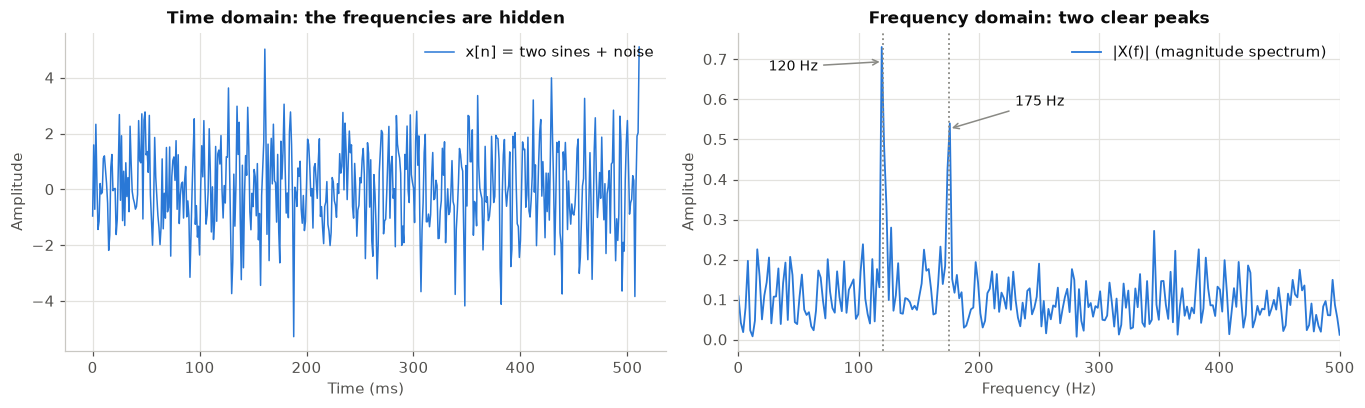

True frequencies: 120 Hz and 175 Hz
DFT frequency spacing: Δf = fs/N = 1.953 Hz


In [2]:
# ---- Example signal: two sines + white noise ----
fs   = 1000.0                 # sampling frequency (Hz)
N    = 512                    # number of samples
n    = np.arange(N)
t    = n / fs                 # time axis (s)

f1, f2 = 120.0, 175.0         # the hidden true frequencies (Hz)
clean  = 1.0 * np.sin(2*np.pi*f1*t) + 0.7 * np.sin(2*np.pi*f2*t)
noise  = 1.2 * rng.standard_normal(N)
x      = clean + noise

# one-sided magnitude spectrum
X    = np.fft.rfft(x)
freq = np.fft.rfftfreq(N, d=1/fs)
mag  = np.abs(X) / N * 2                       # scaled to amplitude

fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.8))

ax[0].plot(t*1000, x, color=C_PER, lw=1.0, label="x[n] = two sines + noise")
ax[0].set_xlabel("Time (ms)")
ax[0].set_ylabel("Amplitude")
ax[0].set_title("Time domain: the frequencies are hidden")
ax[0].legend(loc="upper right")

ax[1].plot(freq, mag, color=C_PER, lw=1.2, label="|X(f)| (magnitude spectrum)")
ax[1].axvline(f1, color=C_MUTE, ls=":", lw=1.2)
ax[1].axvline(f2, color=C_MUTE, ls=":", lw=1.2)
ax[1].annotate(f"{f1:.0f} Hz", xy=(f1, mag.max()*0.95), xytext=(f1-95, mag.max()*0.92),
               color=C_TRUE, fontsize=9,
               arrowprops=dict(arrowstyle="->", color=C_MUTE, lw=1))
ax[1].annotate(f"{f2:.0f} Hz", xy=(f2, mag.max()*0.72), xytext=(f2+55, mag.max()*0.80),
               color=C_TRUE, fontsize=9,
               arrowprops=dict(arrowstyle="->", color=C_MUTE, lw=1))
ax[1].set_xlabel("Frequency (Hz)")
ax[1].set_ylabel("Amplitude")
ax[1].set_title("Frequency domain: two clear peaks")
ax[1].set_xlim(0, fs/2)
ax[1].legend(loc="upper right")

plt.tight_layout(); plt.show()

print(f"True frequencies: {f1:.0f} Hz and {f2:.0f} Hz")
print(f"DFT frequency spacing: Δf = fs/N = {fs/N:.3f} Hz")

### What the plots show

In the time domain you can hardly tell what is inside. In the frequency domain the two peaks at
120 Hz and 175 Hz stand clear of the noise.

Look closely at the noise floor, though: **it is not smooth.** It is rough grass that jumps up and
down. This is the problem the whole notebook is about, and Part 4 proves that the grass
**never gets smoother**, however long you record.

## 1.2 From the DTFT to the DFT

For a discrete-time signal $x[n]$, the **DTFT** (discrete-time Fourier transform) is

$$X(f) \;=\; \sum_{n=-\infty}^{\infty} x[n]\, e^{-j 2\pi f n}$$

where $f$ is the normalized frequency in cycles per sample. $X(f)$ is a **continuous** function
with period 1.

A computer cannot store a continuous function, and we only have $N$ samples, so we compute the
**DFT**, which *samples* $X(f)$ at $N$ evenly spaced frequencies:

$$X[k] \;=\; \sum_{n=0}^{N-1} x[n]\, e^{-j 2\pi k n / N}
\;=\; X(f)\Big|_{f = k/N}, \qquad k = 0,1,\dots,N-1$$

**The DFT is simply the DTFT sampled on a frequency grid.** We can check this numerically by
approximating the DTFT with heavy zero-padding.

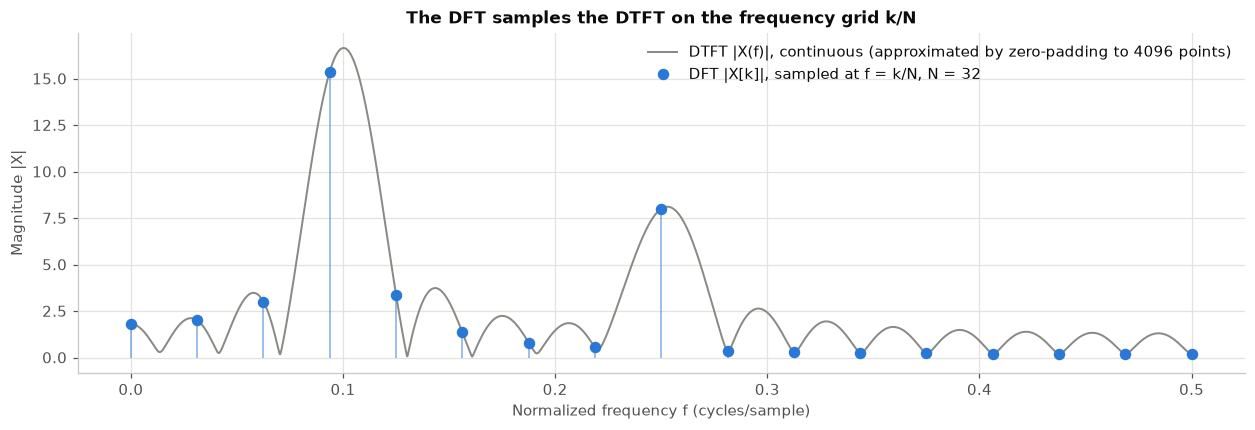

Largest difference between DFT points and the DTFT at the same frequencies = 1.776e-15
→ zero to machine precision, so the DFT is a sampled DTFT


In [3]:
# ---- The DFT is the DTFT, sampled ----
Ns = 32
ns = np.arange(Ns)
xs = np.cos(2*np.pi*0.1*ns) + 0.5*np.cos(2*np.pi*0.25*ns)

# Approximate DTFT: zero-pad heavily, then FFT, for a near-continuous curve
NFFT_dense = 4096
X_dtft = np.fft.rfft(xs, NFFT_dense)
f_dtft = np.fft.rfftfreq(NFFT_dense)          # 0 … 0.5

# N-point DFT = samples at f = k/N
X_dft = np.fft.rfft(xs)
f_dft = np.fft.rfftfreq(Ns)

fig, ax = plt.subplots(figsize=(11.5, 4))
ax.plot(f_dtft, np.abs(X_dtft), color=C_MUTE, lw=1.3,
        label="DTFT |X(f)|, continuous (approximated by zero-padding to 4096 points)")
ax.plot(f_dft, np.abs(X_dft), "o", color=C_PER, ms=6.5, zorder=3,
        label=f"DFT |X[k]|, sampled at f = k/N, N = {Ns}")
ax.vlines(f_dft, 0, np.abs(X_dft), color=C_PER, lw=1.1, alpha=0.55)
ax.set_xlabel("Normalized frequency f (cycles/sample)")
ax.set_ylabel("Magnitude |X|")
ax.set_title("The DFT samples the DTFT on the frequency grid k/N")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

# Numerical check: each DFT point must equal the DTFT at the same frequency
idx  = (f_dft * NFFT_dense).astype(int)
err  = np.max(np.abs(X_dtft[idx] - X_dft))
print(f"Largest difference between DFT points and the DTFT at the same frequencies = {err:.3e}")
print("→ zero to machine precision, so the DFT is a sampled DTFT")

The difference is around $10^{-14}$, which is floating-point rounding error: the DFT equals the
DTFT at $f = k/N$.

One caution that matters in Part 5: zero-padding makes the curve *finer*, but it does not
*resolve* frequencies any better, because it adds no new data. It only draws the same curve with
more points.

# Part 2. Autocorrelation, PSD and the Wiener–Khinchin theorem

## 2.1 The trouble with random signals

Part 1 works well for **deterministic** signals such as sine waves. Noise is a
**random process**, and that raises two problems:

1. **Unbounded energy.** A random signal that runs forever has $\sum |x[n]|^2 = \infty$, so the
   DTFT in the usual sense *does not converge*, and "the $X(f)$ of white noise" does not exist.
2. **Every measurement differs.** Two recordings give two different $X(f)$.
   Which one is "the right spectrum"?

The way out is to stop describing one realization at a time and describe the signal by its
statistics.

## 2.2 WSS processes and autocorrelation

We assume the signal is **wide-sense stationary (WSS)**:

- constant mean: $E\{x[n]\} = \mu$ (from here on, $\mu = 0$)
- the correlation between two samples depends only on how far apart they are, not on where they are

The **autocorrelation function (ACF)** is

$$\boxed{\;r_{xx}[m] \;=\; E\{\,x[n+m]\,x^{*}[n]\,\}\;}$$

$r_{xx}[m]$ says how strongly samples $m$ apart are related.

- $r_{xx}[0] = E\{|x[n]|^2\}$ is the **average power** of the signal
- $|r_{xx}[m]| \le r_{xx}[0]$ for every $m$
- $r_{xx}[-m] = r_{xx}^{*}[m]$ (Hermitian symmetry)

## 2.3 The PSD and the Wiener–Khinchin theorem

The **power spectral density (PSD)** is the DTFT of the ACF:

$$\boxed{\;S_{xx}(f) \;=\; \sum_{m=-\infty}^{\infty} r_{xx}[m]\, e^{-j2\pi f m}\;}$$

The **Wiener–Khinchin theorem** says this is equivalent to a second definition:

$$S_{xx}(f) \;=\; \lim_{N\to\infty} E\left\{ \frac{1}{N}
\left| \sum_{n=0}^{N-1} x[n] e^{-j2\pi f n} \right|^{2} \right\}$$

The quantity inside the braces is exactly what we will call the *periodogram*, so the theorem is
what lets us use the periodogram to estimate the PSD. It comes with two conditions, and those two
conditions cause every problem that follows:

- $\lim_{N\to\infty}$: the data must be **infinitely long** (we have $N$ samples, which causes **bias**)
- $E\{\cdot\}$: we must **average many runs** (we have one, which causes **variance**)

> Bartlett's and Welch's methods both try to build the $E\{\cdot\}$ out of the one data set we have.

Here is the ACF of three kinds of signal.

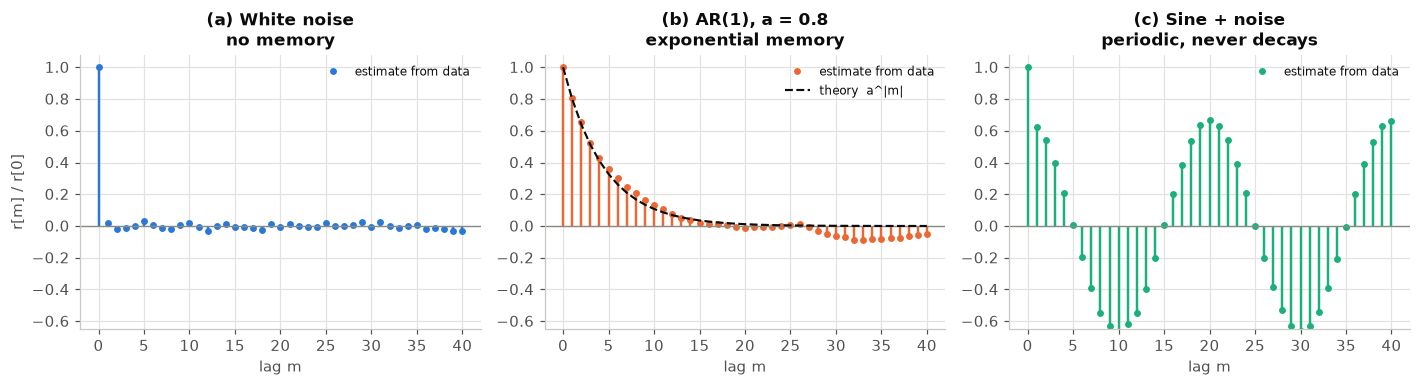

What to notice:
  (a) white noise: r[m] ≈ 0 for every m ≠ 0  → flat spectrum
  (b) AR(1): r[m] decays as a^|m| = 0.8^|m| → spectrum tilted toward low frequencies
  (c) sine: r[m] never decays and keeps oscillating → spectrum has a sharp peak


In [4]:
# ---- ACF of three kinds of signal ----
M = 4000
lag_max = 40

# (a) white noise: no correlation across time
w = rng.standard_normal(M)

# (b) AR(1): x[n] = a·x[n-1] + w[n] , coloured noise with some memory of the past
a_ar = 0.8
x_ar = sig.lfilter([1.0], [1.0, -a_ar], rng.standard_normal(M + 500))[500:]

# (c) sine + noise: the ACF keeps oscillating
x_sin = np.sin(2*np.pi*0.05*np.arange(M)) + 0.5*rng.standard_normal(M)

def acf_biased(x, lag_max):
    """Biased ACF estimate r[m] = (1/N) Σ x[n+m] x*[n], for lags 0…lag_max."""
    x = x - x.mean()
    N = len(x)
    r = np.correlate(x, x, mode="full") / N          # the middle index is lag 0
    mid = N - 1
    return r[mid: mid + lag_max + 1]

lags = np.arange(lag_max + 1)
titles = ["(a) White noise\nno memory",
          f"(b) AR(1), a = {a_ar}\nexponential memory",
          "(c) Sine + noise\nperiodic, never decays"]
signals = [w, x_ar, x_sin]
colors  = [C_PER, C_BAR, C_WEL]

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for k, (s, ttl, col) in enumerate(zip(signals, titles, colors)):
    r = acf_biased(s, lag_max)
    r = r / r[0]                                     # normalize so that r[0] = 1
    ax[k].vlines(lags, 0, r, color=col, lw=1.6)
    ax[k].plot(lags, r, "o", color=col, ms=3.5, label="estimate from data")
    ax[k].axhline(0, color=C_MUTE, lw=0.9)
    ax[k].set_title(ttl)
    ax[k].set_xlabel("lag m")
    ax[k].set_ylim(-0.65, 1.08)
    if k == 0:
        ax[k].set_ylabel("r[m] / r[0]")

# Overlay the AR(1) theory: r[m] ∝ a^|m|
ax[1].plot(lags, a_ar**lags, "--", color=C_TRUE, lw=1.4, label="theory  a^|m|")
ax[0].legend(loc="upper right", fontsize=8)
ax[1].legend(loc="upper right", fontsize=8)
ax[2].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

print("What to notice:")
print("  (a) white noise: r[m] ≈ 0 for every m ≠ 0  → flat spectrum")
print(f"  (b) AR(1): r[m] decays as a^|m| = {a_ar}^|m| → spectrum tilted toward low frequencies")
print("  (c) sine: r[m] never decays and keeps oscillating → spectrum has a sharp peak")

### Checking Wiener–Khinchin numerically

For the AR(1) process $x[n] = a\,x[n-1] + w[n]$, where $w$ is white noise with variance
$\sigma^2$, both sides have closed forms:

$$r_{xx}[m] = \frac{\sigma^{2}}{1-a^{2}}\, a^{|m|}
\qquad\text{and}\qquad
S_{xx}(f) = \frac{\sigma^{2}}{\left|1 - a\,e^{-j2\pi f}\right|^{2}}$$

If the theorem holds, the DTFT of $r_{xx}[m]$ must give exactly $S_{xx}(f)$.

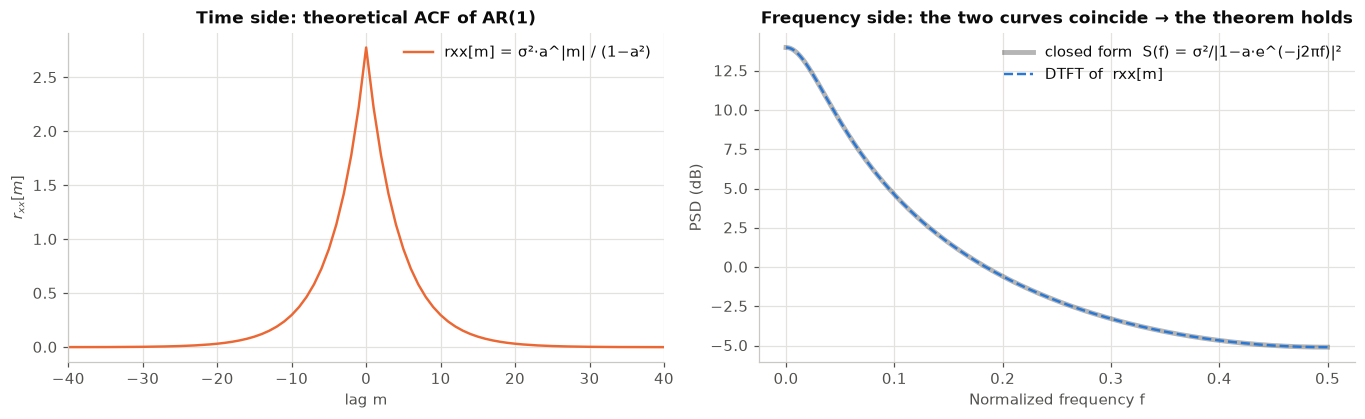

Largest difference between the two sides = 2.487e-14
→ the DTFT of the autocorrelation gives the PSD (Wiener–Khinchin)


In [5]:
# ---- Check Wiener–Khinchin: DTFT{ r[m] } == S(f) ----
a_wk, sigma2 = 0.8, 1.0
f_grid = np.linspace(0, 0.5, 1024)

# Right-hand side: closed-form PSD
S_closed = sigma2 / np.abs(1 - a_wk*np.exp(-2j*np.pi*f_grid))**2

# Left-hand side: DTFT of the theoretical ACF, truncated at a lag large enough not to matter
Mmax = 300
m    = np.arange(-Mmax, Mmax + 1)
r_th = sigma2 / (1 - a_wk**2) * a_wk**np.abs(m)
S_from_acf = np.real(r_th @ np.exp(-2j*np.pi*np.outer(m, f_grid)))

fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9))

ax[0].plot(m, r_th, color=C_BAR, lw=1.6,
           label="rxx[m] = σ²·a^|m| / (1−a²)")
ax[0].set_xlim(-40, 40)
ax[0].set_xlabel("lag m"); ax[0].set_ylabel(r"$r_{xx}[m]$")
ax[0].set_title("Time side: theoretical ACF of AR(1)")
ax[0].legend(loc="upper right")

ax[1].plot(f_grid, 10*np.log10(S_closed), color=C_TRUE, lw=3.2, alpha=0.30,
           label="closed form  S(f) = σ²/|1−a·e^(−j2πf)|²")
ax[1].plot(f_grid, 10*np.log10(S_from_acf), "--", color=C_PER, lw=1.6,
           label="DTFT of  rxx[m]")
ax[1].set_xlabel("Normalized frequency f"); ax[1].set_ylabel("PSD (dB)")
ax[1].set_title("Frequency side: the two curves coincide → the theorem holds")
ax[1].legend(loc="upper right")

plt.tight_layout(); plt.show()

print(f"Largest difference between the two sides = {np.max(np.abs(S_closed - S_from_acf)):.3e}")
print("→ the DTFT of the autocorrelation gives the PSD (Wiener–Khinchin)")

The two curves overlap so closely that one is drawn thick and faint and the other dashed. The rest
of the notebook builds on this relation:

$$\text{ACF} \;\xleftrightarrow{\;\;\text{DTFT}\;\;}\; \text{PSD}$$

If we can estimate the ACF, we can estimate the PSD. That is what the periodogram does, often
without its user knowing, as the next part proves.

# Part 3. The periodogram: definition and proof

## 3.1 Definition

The **periodogram** of $N$ samples is

$$\boxed{\;\hat{S}_{\text{per}}(f) \;=\; \frac{1}{N}\left|\,\sum_{n=0}^{N-1} x[n]\,e^{-j2\pi f n}\right|^{2}
\;=\; \frac{1}{N}\left|X(f)\right|^{2}\;}$$

The name comes from Arthur Schuster (1898), who used it to look for hidden periods in sunspot data.

It looks like "square the FFT and divide by N", and it is. The question is **why that estimates
the PSD at all.**

## 3.2 Theorem: the periodogram is the DTFT of the biased ACF

> **Theorem.** The periodogram equals the DTFT of the biased autocorrelation estimate:
> $$\hat{S}_{\text{per}}(f) \;=\; \sum_{m=-(N-1)}^{N-1} \hat{r}_{xx}[m]\, e^{-j2\pi f m}
> \qquad\text{where}\qquad
> \hat{r}_{xx}[m] \;=\; \frac{1}{N}\sum_{n} x[n+m]\,x^{*}[n]$$

### Proof

Start from the definition and expand $|X(f)|^2 = X(f)X^{*}(f)$ into a double sum:

$$\hat{S}_{\text{per}}(f)
= \frac{1}{N} \left(\sum_{n=0}^{N-1} x[n]e^{-j2\pi f n}\right)
             \left(\sum_{k=0}^{N-1} x^{*}[k]e^{+j2\pi f k}\right)
= \frac{1}{N} \sum_{n=0}^{N-1}\sum_{k=0}^{N-1} x[n]\,x^{*}[k]\; e^{-j2\pi f (n-k)}$$

The key step is a change of variable: let $m = n - k$, the *distance* between the two indices,
and group all the terms with the same $m$. Writing $n = k+m$ gives

$$\hat{S}_{\text{per}}(f)
= \sum_{m=-(N-1)}^{N-1} e^{-j2\pi f m}
  \underbrace{\left[\frac{1}{N}\sum_{k} x[k+m]\,x^{*}[k]\right]}_{\textstyle \hat{r}_{xx}[m]}$$

$m$ runs from $-(N-1)$ to $N-1$ because both indices lie in $[0, N-1]$, so they can differ by at
most $N-1$. The inner sum runs only over the $k$ for which both $k$ and $k+m$ stay inside the
data, which leaves $N - |m|$ terms.  $\blacksquare$

### Why "biased"

The sum has $N - |m|$ terms but is divided by $N$, not by $N-|m|$. That is where the bias comes
from, and it is the subject of Part 4.

First, a numerical check of the theorem: compute it both ways and compare.

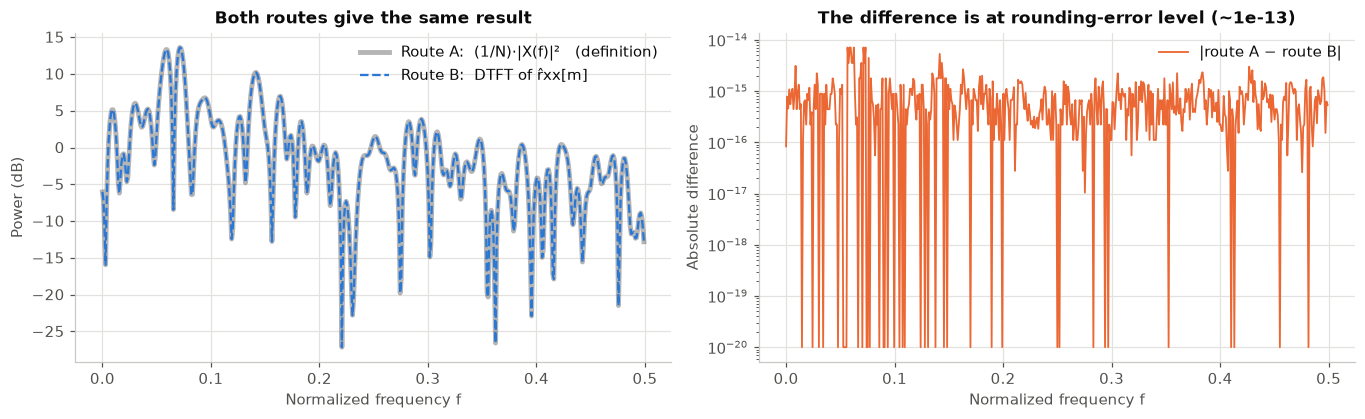

Largest difference        = 7.105e-15
Typical signal level = 1.707e+00
Relative difference       = 4.162e-15  → theorem confirmed


In [6]:
# ---- Check the theorem: periodogram == DTFT of the biased ACF ----
N_pf  = 128
NFFT  = 1024
x_pf  = sig.lfilter([1.0], [1.0, -0.7], rng.standard_normal(N_pf + 300))[300:]

# ---- Route A: straight from the definition, (1/N)|FFT|² ----
P_direct = np.abs(np.fft.fft(x_pf, NFFT))**2 / N_pf

# ---- Route B: biased ACF first, then its DTFT ----
r_full = np.correlate(x_pf, x_pf, mode="full") / N_pf     # lag = -(N-1) … (N-1)
lags   = np.arange(-(N_pf - 1), N_pf)
seq    = np.zeros(NFFT)
seq[lags % NFFT] = r_full        # negative lags go at the end of the array (DFT periodicity)
P_via_acf = np.real(np.fft.fft(seq))

f_ax = np.fft.fftfreq(NFFT)[:NFFT//2]
sl   = slice(0, NFFT//2)

fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9))

ax[0].plot(f_ax, 10*np.log10(P_direct[sl]), color=C_TRUE, lw=3.2, alpha=0.30,
           label="Route A:  (1/N)·|X(f)|²   (definition)")
ax[0].plot(f_ax, 10*np.log10(P_via_acf[sl]), "--", color=C_PER, lw=1.5,
           label="Route B:  DTFT of r̂xx[m]")
ax[0].set_xlabel("Normalized frequency f"); ax[0].set_ylabel("Power (dB)")
ax[0].set_title("Both routes give the same result")
ax[0].legend(loc="upper right")

err = np.abs(P_direct - P_via_acf)
ax[1].semilogy(f_ax, err[sl] + 1e-20, color=C_BAR, lw=1.2,
               label="|route A − route B|")
ax[1].set_xlabel("Normalized frequency f"); ax[1].set_ylabel("Absolute difference")
ax[1].set_title("The difference is at rounding-error level (~1e-13)")
ax[1].legend(loc="upper right")

plt.tight_layout(); plt.show()

print(f"Largest difference        = {err.max():.3e}")
print(f"Typical signal level = {P_direct.mean():.3e}")
print(f"Relative difference       = {err.max()/P_direct.mean():.3e}  → theorem confirmed")

The relative difference is around $10^{-15}$, rounding error only, so the theorem holds.

This is the most important point in the notebook:

> When you compute a periodogram, you are taking the DTFT of an ACF *estimated with bias*,
> whether you know it or not. The quality of the periodogram is set entirely by the quality of
> that ACF estimate.

## 3.3 ACF estimators: biased and unbiased

There are two ways to estimate $r_{xx}[m]$ from $N$ samples:

$$\hat{r}_{\text{biased}}[m] = \frac{1}{N}\sum_{n=0}^{N-1-|m|} x[n+|m|]x^{*}[n]
\qquad
\hat{r}_{\text{unbiased}}[m] = \frac{1}{N-|m|}\sum_{n=0}^{N-1-|m|} x[n+|m|]x^{*}[n]$$

Take the expected value of each, using $E\{x[n+m]x^*[n]\} = r_{xx}[m]$ for every term and
$N - |m|$ terms in total:

$$E\{\hat{r}_{\text{biased}}[m]\} = \frac{N-|m|}{N}\,r_{xx}[m]
= \underbrace{\left(1 - \frac{|m|}{N}\right)}_{\textstyle w_{B}[m]}\, r_{xx}[m],
\qquad
E\{\hat{r}_{\text{unbiased}}[m]\} = r_{xx}[m]$$

The second estimator has *no bias*, yet **we use the first**, for two reasons:

1. The second has **exploding variance** at high lags. Near $m = N$ only a few terms are left to
   average (at $m = N-1$, just one), and they are still divided by a small number.
2. The second is **not guaranteed to be positive semi-definite**, so its DTFT can go negative,
   which is impossible for a PSD.

The first always gives $\hat{S}_{\text{per}}(f) = \frac{1}{N}|X(f)|^2 \ge 0$.

**The factor $w_B[m] = 1 - |m|/N$ is a triangular window**, the **Bartlett window**. Nobody
applies it on purpose; it comes from the data being finite.

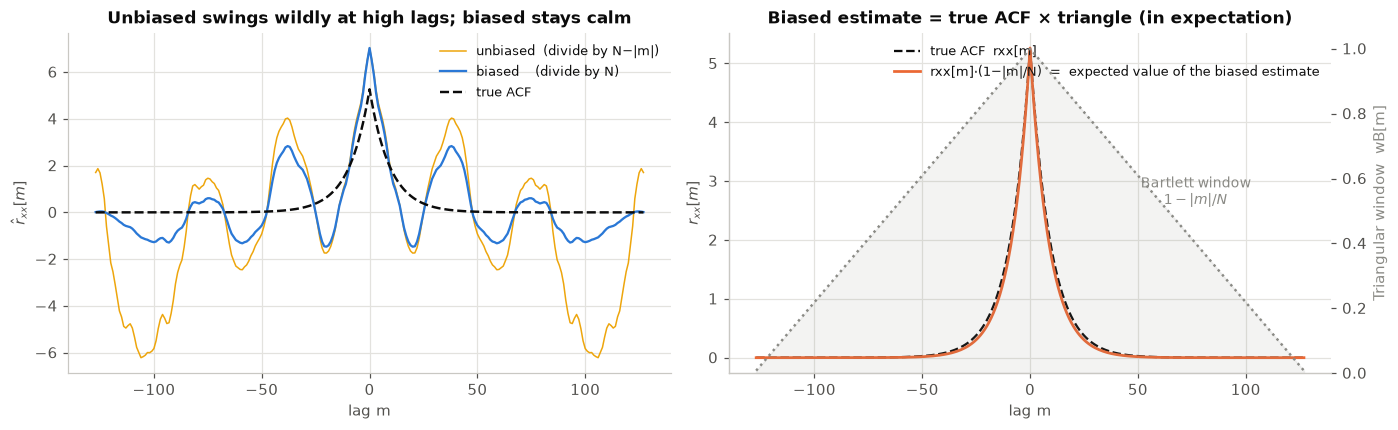

Spread at high lags (|m| > 0.8N):
   unbiased :    2.750   ← swings hard
   biased   :    0.413   ← held down by the triangle


In [7]:
# ---- Biased vs unbiased ACF: where the triangular window comes from ----
N_acf  = 128
a_acf  = 0.9
x_acf  = sig.lfilter([1.0], [1.0, -a_acf], rng.standard_normal(N_acf + 400))[400:]

lg     = np.arange(-(N_acf-1), N_acf)
raw    = np.correlate(x_acf, x_acf, mode="full")
r_bias = raw / N_acf                      # divide by a fixed N
r_unb  = raw / (N_acf - np.abs(lg))       # divide by the actual number of terms
r_true = (1/(1-a_acf**2)) * a_acf**np.abs(lg)     # true ACF of the AR(1) process
w_bart = 1 - np.abs(lg)/N_acf                     # triangular window

fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.0))

ax[0].plot(lg, r_unb,  color=C_ALT, lw=1.0, alpha=0.95, label="unbiased  (divide by N−|m|)")
ax[0].plot(lg, r_bias, color=C_PER, lw=1.5,             label="biased    (divide by N)")
ax[0].plot(lg, r_true, "--", color=C_TRUE, lw=1.6,      label="true ACF")
ax[0].set_xlabel("lag m"); ax[0].set_ylabel(r"$\hat{r}_{xx}[m]$")
ax[0].set_title("Unbiased swings wildly at high lags; biased stays calm")
ax[0].legend(loc="upper right", fontsize=8.5)

# Show that biased = true × triangle (on average)
ax[1].plot(lg, r_true, "--", color=C_TRUE, lw=1.5, label="true ACF  rxx[m]")
ax[1].plot(lg, r_true*w_bart, color=C_BAR, lw=1.8,
           label="rxx[m]·(1−|m|/N)  =  expected value of the biased estimate")
ax2 = ax[1].twinx()
ax2.plot(lg, w_bart, ":", color=C_MUTE, lw=1.6)
ax2.fill_between(lg, 0, w_bart, color=C_MUTE, alpha=0.10)
ax2.set_ylabel("Triangular window  wB[m]", color=C_MUTE)
ax2.set_ylim(0, 1.05); ax2.grid(False)
ax2.text(0.60*N_acf, 0.52, "Bartlett window\n$1-|m|/N$", color=C_MUTE,
         fontsize=9, ha="center")
ax[1].set_xlabel("lag m"); ax[1].set_ylabel(r"$r_{xx}[m]$")
ax[1].set_title("Biased estimate = true ACF × triangle (in expectation)")
ax[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout(); plt.show()

hi = np.abs(lg) > 0.8*N_acf
print(f"Spread at high lags (|m| > 0.8N):")
print(f"   unbiased : {r_unb[hi].std():8.3f}   ← swings hard")
print(f"   biased   : {r_bias[hi].std():8.3f}   ← held down by the triangle")

The left plot shows why we accept the bias. The unbiased estimate (yellow) swings wildly at high
lags because it divides by small numbers, while the triangular window presses the biased one
(blue) toward zero, which makes it far more stable.

**We trade bias for lower variance.** This trade comes back again and again in the notebook.

# Part 4. Statistical properties: why the periodogram fails in practice

A good estimator needs two properties as $N \to \infty$:

1. **Asymptotically unbiased:** $E\{\hat{S}(f)\} \to S(f)$, so it is right on average
2. **Consistent:** $\operatorname{Var}\{\hat{S}(f)\} \to 0$, so more data makes it steadier

We will prove that the periodogram **passes the first and fails the second completely.**

## 4.1 Proof of the bias: the Fejér kernel

Take the theorem from Part 3 and take expectations on both sides:

$$E\{\hat{S}_{\text{per}}(f)\}
= \sum_{m=-(N-1)}^{N-1} E\{\hat{r}_{xx}[m]\}\, e^{-j2\pi f m}
= \sum_{m=-(N-1)}^{N-1} \left(1-\frac{|m|}{N}\right) r_{xx}[m]\, e^{-j2\pi f m}$$

The right-hand side is the DTFT of the **product** $w_B[m]\cdot r_{xx}[m]$. By the multiplication
theorem, multiplying in time is convolving in frequency:

$$\boxed{\;E\{\hat{S}_{\text{per}}(f)\} \;=\; S_{xx}(f) \circledast W_{B}(f)
\;=\; \int_{-1/2}^{1/2} S_{xx}(\nu)\, W_{B}(f-\nu)\, d\nu \;}$$

where $W_B(f)$, the DTFT of the triangular window, is the **Fejér kernel**:

$$W_{B}(f) \;=\; \frac{1}{N}\left(\frac{\sin(\pi f N)}{\sin(\pi f)}\right)^{2} \;\ge 0$$

### What it means

**The periodogram gives $S(f)$ blurred by the Fejér kernel**, like a photo taken through a lens
that is slightly out of focus.

- The main lobe is about $2/N$ wide, which **limits the frequency resolution**
- The highest side lobe is about $-13$ dB, which **causes spectral leakage**
- As $N \to \infty$, $W_B(f) \to \delta(f)$, so $E\{\hat{S}\} \to S$: the periodogram is
  **asymptotically unbiased**

Here is the Fejér kernel for several values of $N$.

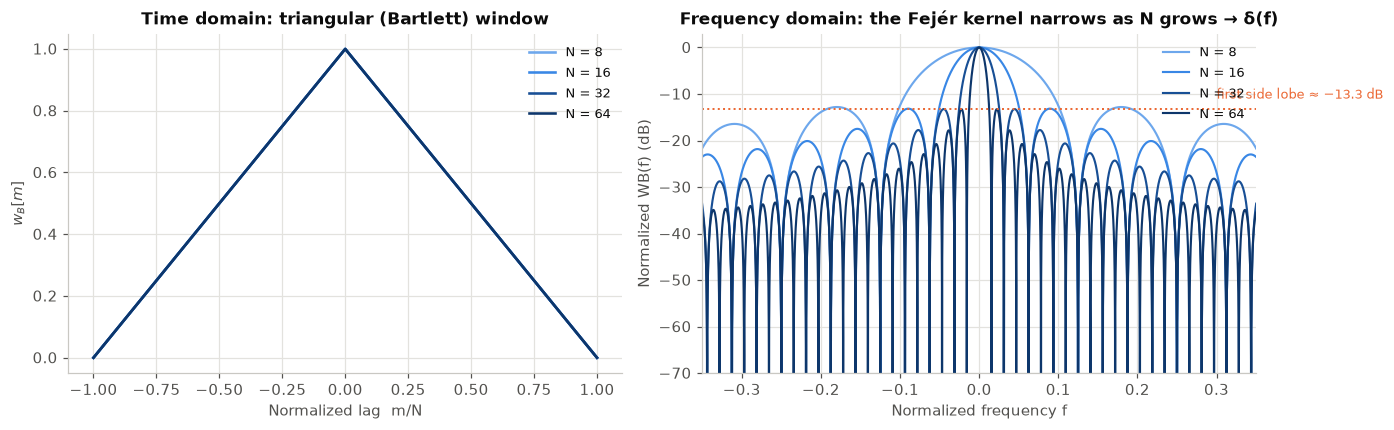

N =   8 : main-lobe width (null-to-null) = 2/N = 0.2500 cycles/sample
N =  16 : main-lobe width (null-to-null) = 2/N = 0.1250 cycles/sample
N =  32 : main-lobe width (null-to-null) = 2/N = 0.0625 cycles/sample
N =  64 : main-lobe width (null-to-null) = 2/N = 0.0312 cycles/sample


In [8]:
# ---- Fejér kernel: the triangular window and its effect in frequency ----
f_fk = np.linspace(-0.5, 0.5, 8001)

def fejer(f, N):
    """Fejér kernel W_B(f) = (1/N)·(sin(πfN)/sin(πf))² , with f→0 handled separately."""
    num = np.sin(np.pi*f*N)
    den = np.sin(np.pi*f)
    out = np.empty_like(f)
    small = np.abs(den) < 1e-12
    out[~small] = (num[~small]/den[~small])**2 / N
    out[small]  = N                      # the limit at f = 0 is N
    return out

fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.0))

Ns_demo = [8, 16, 32, 64]
for N_d, col in zip(Ns_demo, [BLUES[2], BLUES[3], BLUES[5], BLUES[6]]):
    mm = np.arange(-N_d, N_d+1)
    ax[0].plot(mm/N_d, np.maximum(1-np.abs(mm)/N_d, 0), color=col, lw=1.7,
               label=f"N = {N_d}")
    W = fejer(f_fk, N_d)
    ax[1].plot(f_fk, 10*np.log10(W/W.max() + 1e-16), color=col, lw=1.4,
               label=f"N = {N_d}")

ax[0].set_xlabel("Normalized lag  m/N"); ax[0].set_ylabel("$w_B[m]$")
ax[0].set_title("Time domain: triangular (Bartlett) window")
ax[0].legend(loc="upper right", fontsize=8.5)

ax[1].axhline(-13.3, color=C_BAR, ls=":", lw=1.3)
ax[1].text(0.30, -11.0, "first side lobe ≈ −13.3 dB", color=C_BAR, fontsize=8.5)
ax[1].set_xlim(-0.35, 0.35); ax[1].set_ylim(-70, 3)
ax[1].set_xlabel("Normalized frequency f"); ax[1].set_ylabel("Normalized WB(f) (dB)")
ax[1].set_title("Frequency domain: the Fejér kernel narrows as N grows → δ(f)")
ax[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout(); plt.show()

for N_d in Ns_demo:
    print(f"N = {N_d:3d} : main-lobe width (null-to-null) = 2/N = {2/N_d:.4f} cycles/sample")

### Checking the bias by simulation

We compare three curves:

1. The **true PSD** $S(f)$, from the AR closed form
2. The **theoretical expectation** $\sum_m (1-|m|/N)\,r_{xx}[m]e^{-j2\pi fm}$, computed straight from
   the formula we proved
3. The **Monte Carlo mean**: the average periodogram over 5,000 realizations

If the proof is right, 2 and 3 must coincide, and both must differ somewhat from 1. That
difference is the bias.

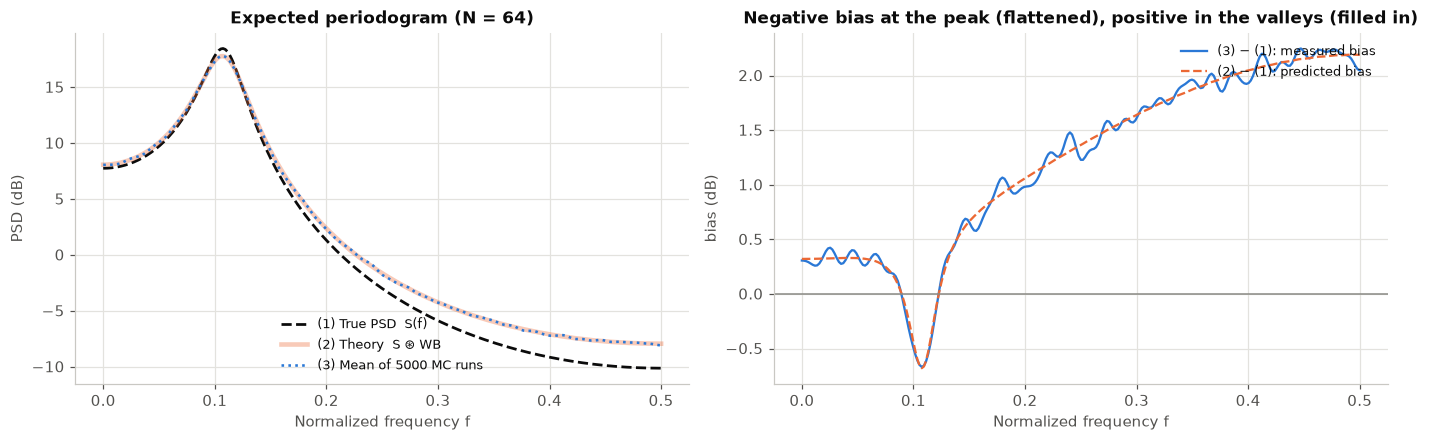

Theory (2) vs Monte Carlo (3): largest gap 0.171 dB
Largest bias against the true PSD         : 2.19 dB


In [9]:
# ---- Check the bias: mean periodogram = S(f) ⊛ Fejér ----
# An AR(2) process with a sharp peak makes the bias easy to see
a_coef = np.array([1.0, -1.40, 0.81])      # AR(2) denominator, which gives a resonance
N_b    = 64                                 # a small N makes the bias stand out
NF     = 512
f_b    = np.fft.rfftfreq(NF)

# (1) True PSD from the closed form: S(f) = σ²/|A(e^{j2πf})|²
#     worN is a frequency array, so H is evaluated on exactly the rfftfreq grid
_, H   = sig.freqz([1.0], a_coef, worN=f_b, fs=1.0)
S_true = np.abs(H)**2

# The process's true ACF (inverse transform of a very fine PSD)
NF_fine = 8192
_, Hf   = sig.freqz([1.0], a_coef, worN=NF_fine, whole=True)
r_true_full = np.real(np.fft.ifft(np.abs(Hf)**2))

# (2) Theoretical expectation: DTFT of (1-|m|/N)·r[m]
m_b   = np.arange(-(N_b-1), N_b)
r_b   = r_true_full[np.abs(m_b)]
S_exp = np.real((r_b*(1-np.abs(m_b)/N_b)) @ np.exp(-2j*np.pi*np.outer(m_b, f_b)))

# (3) Monte Carlo
n_mc  = 5000
acc   = np.zeros(len(f_b))
for _ in range(n_mc):
    xb  = sig.lfilter([1.0], a_coef, rng.standard_normal(N_b + 500))[500:]
    acc += np.abs(np.fft.rfft(xb, NF))**2 / N_b
S_mc = acc / n_mc

fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.1))

ax[0].plot(f_b, 10*np.log10(S_true), "--", color=C_TRUE, lw=1.8, label="(1) True PSD  S(f)")
ax[0].plot(f_b, 10*np.log10(S_exp),  color=C_BAR, lw=3.0, alpha=0.35,
           label="(2) Theory  S ⊛ WB")
ax[0].plot(f_b, 10*np.log10(S_mc), ":", color=C_PER, lw=1.7,
           label=f"(3) Mean of {n_mc} MC runs")
ax[0].set_xlabel("Normalized frequency f"); ax[0].set_ylabel("PSD (dB)")
ax[0].set_title(f"Expected periodogram (N = {N_b})")
ax[0].legend(loc="lower center", fontsize=8.5)

ax[1].plot(f_b, 10*np.log10(S_mc) - 10*np.log10(S_true), color=C_PER, lw=1.5,
           label="(3) − (1): measured bias")
ax[1].plot(f_b, 10*np.log10(S_exp) - 10*np.log10(S_true), "--", color=C_BAR, lw=1.5,
           label="(2) − (1): predicted bias")
ax[1].axhline(0, color=C_MUTE, lw=1.0)
ax[1].set_xlabel("Normalized frequency f"); ax[1].set_ylabel("bias (dB)")
ax[1].set_title("Negative bias at the peak (flattened), positive in the valleys (filled in)")
ax[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout(); plt.show()

print(f"Theory (2) vs Monte Carlo (3): largest gap {np.max(np.abs(10*np.log10(S_exp/S_mc))):.3f} dB")
print(f"Largest bias against the true PSD         : {np.max(np.abs(10*np.log10(S_exp/S_true))):.2f} dB")

Theory and Monte Carlo coincide (they differ by a small fraction of a dB, which is sampling
noise), so the proof of the bias is correct.

The right plot shows the classic shape of the bias:
- Peaks are pushed down (negative bias), because the blur spreads the energy of a peak around it
- Valleys are filled in (positive bias), because they collect the energy leaking from the peaks

The higher the dynamic range of the spectrum (tall peaks, deep valleys), the worse the bias.

## 4.2 Proof of the variance: the real problem

For Gaussian white noise with PSD $S(f) = \sigma^2$, one can show that

$$\boxed{\;\operatorname{Var}\{\hat{S}_{\text{per}}(f)\} \;\approx\; S^{2}(f)
\qquad \text{for } 0 < f < 1/2\;}$$

**There is no $N$ on the right-hand side.**

$$\frac{\text{standard deviation}}{\text{mean}}
= \frac{\sqrt{\operatorname{Var}}}{E\{\hat{S}\}} \approx \frac{S(f)}{S(f)} = 1 = 100\%$$

> **The error stays at 100% however many samples you take.**
> With a million samples, it is still 100%,
> so the periodogram **is not a consistent estimator.**

### Why: the intuition

This is the easiest way to see it, and it leads straight to Bartlett and Welch:

- Doubling $N$ gives $N$ new samples, and also $N$ new frequency points
- At each frequency, the amount of data behind the estimate stays the same
- So a larger $N$ gives **more** estimates, but each one is **no better**

$$N \uparrow \;\Rightarrow\; \text{number of frequency points} \uparrow \;\;\text{but}\;\; \text{quality per point} = \text{constant}$$

### The distribution

For a Gaussian process, $\mathrm{Re}\{X(f)\}$ and $\mathrm{Im}\{X(f)\}$ are independent
Gaussians, so $|X(f)|^2$ is a sum of two squared Gaussians:

$$\frac{2\,\hat{S}_{\text{per}}(f)}{S(f)} \;\sim\; \chi^{2}_{2}
\qquad\Longleftrightarrow\qquad
\frac{\hat{S}_{\text{per}}(f)}{S(f)} \;\sim\; \text{Exponential}(1)$$

The exponential distribution has mean 1 and **standard deviation 1**, which confirms the variance
formula above. (At $f = 0$ and $f = 1/2$ the values are purely real, so the distribution is
$\chi^2_1$ with variance $2S^2$, which is worse still.)

The next plot is the most important one in the notebook.

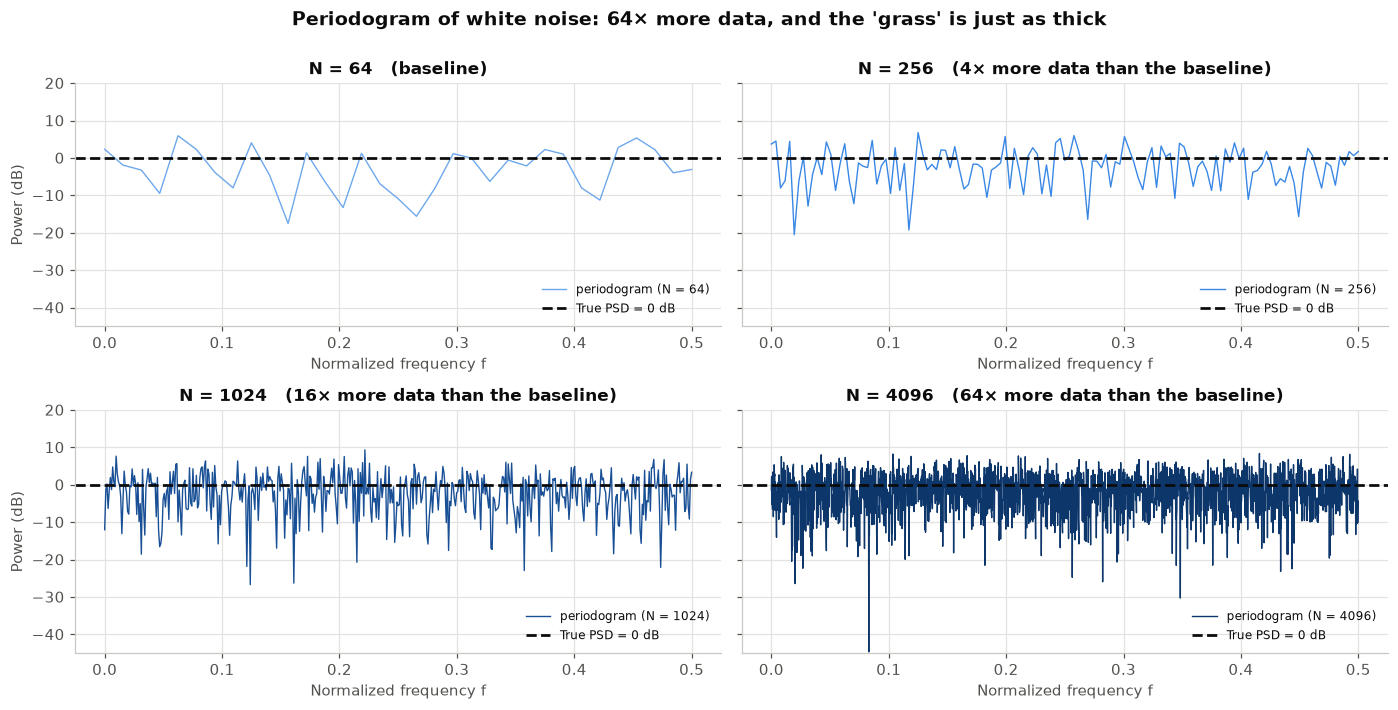

Standard deviation of the estimates (should be near S = 1.0 every time):
   N =    64 :  mean = 0.872   std = 0.862
   N =   256 :  mean = 0.906   std = 0.935
   N =  1024 :  mean = 1.016   std = 1.029
   N =  4096 :  mean = 0.999   std = 0.993


In [10]:
# ---- The key plot: more data never smooths the periodogram ----
sigma  = 1.0
S0     = sigma**2                       # true PSD of white noise (two-sided, fs=1)
N_list = [64, 256, 1024, 4096]

fig, axes = plt.subplots(2, 2, figsize=(12.8, 6.4), sharey=True)

for axk, N_v, col in zip(axes.ravel(), N_list, [BLUES[2], BLUES[3], BLUES[5], BLUES[6]]):
    xv = sigma*rng.standard_normal(N_v)
    Pv = np.abs(np.fft.rfft(xv))**2 / N_v
    fv = np.fft.rfftfreq(N_v)

    axk.plot(fv, 10*np.log10(Pv + 1e-12), color=col, lw=0.9,
             label=f"periodogram (N = {N_v})")
    axk.axhline(10*np.log10(S0), color=C_TRUE, ls="--", lw=1.8,
                label="True PSD = 0 dB")
    axk.set_title(f"N = {N_v}" + ("   (baseline)" if N_v == 64
                 else f"   ({N_v//64}× more data than the baseline)"))
    axk.set_ylim(-45, 20)
    axk.legend(loc="lower right", fontsize=8)
    axk.set_xlabel("Normalized frequency f")

axes[0,0].set_ylabel("Power (dB)"); axes[1,0].set_ylabel("Power (dB)")
fig.suptitle("Periodogram of white noise: 64× more data, and the 'grass' is just as thick",
             fontsize=12.5, fontweight="bold", y=1.00)
plt.tight_layout(); plt.show()

print("Standard deviation of the estimates (should be near S = 1.0 every time):")
for N_v in N_list:
    xv = sigma*rng.standard_normal(N_v)
    Pv = np.abs(np.fft.rfft(xv))**2 / N_v
    print(f"   N = {N_v:5d} :  mean = {Pv.mean():.3f}   std = {Pv.std():.3f}")

The four plots use data lengths up to 64× apart, yet the "grass" is exactly as thick in each.
Only the points get denser.

The printed `std` agrees: it stays near 1.0 every time, as proved ($\sqrt{\operatorname{Var}} \approx S = 1$).

Next, a direct Monte Carlo measurement and a look at the distribution.

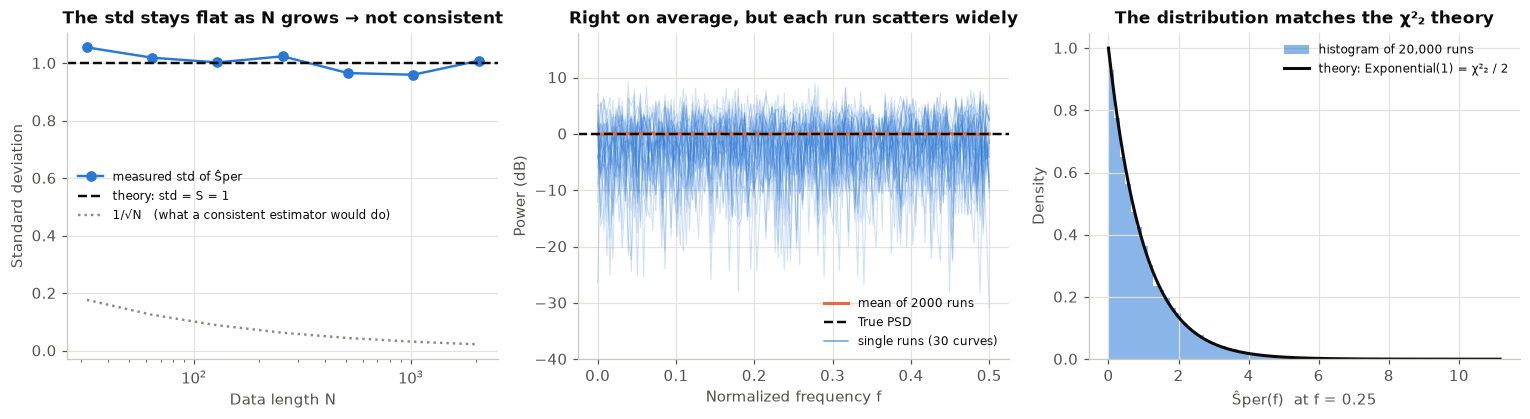

Ensemble mean        = 1.0198   (theory = 1.0)
Ensemble std         = 1.0207   (theory = 1.0)
Std in dB            = 5.642 dB   (theory = 5.57 dB)


In [11]:
# ---- The variance does not shrink with N, and the distribution is exponential ----
N_sweep = [32, 64, 128, 256, 512, 1024, 2048]
n_rep   = 4000
std_at_f, mean_at_f = [], []

for N_v in N_sweep:
    k_test = N_v // 4                                  # look at f = 0.25
    vals = np.empty(n_rep)
    for i in range(n_rep):
        xv = rng.standard_normal(N_v)
        vals[i] = np.abs(np.fft.rfft(xv)[k_test])**2 / N_v
    std_at_f.append(vals.std()); mean_at_f.append(vals.mean())

# keep an ensemble for the histogram (at N = 256)
N_h, k_h = 256, 64
samples = np.array([np.abs(np.fft.rfft(rng.standard_normal(N_h))[k_h])**2 / N_h
                    for _ in range(20000)])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))

# (a) the variance stays put while 1/√N falls
ax[0].semilogx(N_sweep, std_at_f, "o-", color=C_PER, ms=6,
               label="measured std of Ŝper")
ax[0].axhline(1.0, color=C_TRUE, ls="--", lw=1.6, label="theory: std = S = 1")
ax[0].semilogx(N_sweep, 1/np.sqrt(N_sweep), ":", color=C_MUTE, lw=1.6,
               label="1/√N   (what a consistent estimator would do)")
ax[0].set_xlabel("Data length N"); ax[0].set_ylabel("Standard deviation")
ax[0].set_title("The std stays flat as N grows → not consistent")
ax[0].legend(loc="center left", fontsize=8)

# (b) ensemble spaghetti
N_e = 256
fe  = np.fft.rfftfreq(N_e)
for i in range(30):
    Pe = np.abs(np.fft.rfft(rng.standard_normal(N_e)))**2 / N_e
    ax[1].plot(fe, 10*np.log10(Pe+1e-12), color=C_PER, lw=0.7, alpha=0.22)
mean_e = np.mean([np.abs(np.fft.rfft(rng.standard_normal(N_e)))**2 / N_e
                  for _ in range(2000)], axis=0)
ax[1].plot(fe, 10*np.log10(mean_e), color=C_BAR, lw=2.0, label="mean of 2000 runs")
ax[1].axhline(0, color=C_TRUE, ls="--", lw=1.6, label="True PSD")
ax[1].plot([], [], color=C_PER, lw=1.0, alpha=0.7, label="single runs (30 curves)")
ax[1].set_ylim(-40, 18)
ax[1].set_xlabel("Normalized frequency f"); ax[1].set_ylabel("Power (dB)")
ax[1].set_title("Right on average, but each run scatters widely")
ax[1].legend(loc="lower right", fontsize=8)

# (c) histogram vs the exponential distribution
ax[2].hist(samples, bins=70, density=True, color=C_PER, alpha=0.55,
           edgecolor="none", label="histogram of 20,000 runs")
xx = np.linspace(0, samples.max(), 400)
ax[2].plot(xx, stats.expon.pdf(xx, scale=1.0), color=C_TRUE, lw=2.0,
           label="theory: Exponential(1) = χ²₂ / 2")
ax[2].set_xlabel("Ŝper(f)  at f = 0.25"); ax[2].set_ylabel("Density")
ax[2].set_title("The distribution matches the χ²₂ theory")
ax[2].legend(loc="upper right", fontsize=8)

plt.tight_layout(); plt.show()

print(f"Ensemble mean        = {samples.mean():.4f}   (theory = 1.0)")
print(f"Ensemble std         = {samples.std():.4f}   (theory = 1.0)")
print(f"Std in dB            = {np.std(10*np.log10(samples)):.3f} dB   (theory = 5.57 dB)")

### Summary of Part 4

| Property | Result | Meaning |
|---|---|---|
| $E\{\hat{S}\} = S \circledast W_B$ | asymptotically unbiased | right on average, **if** $N$ is large enough |
| $\operatorname{Var}\{\hat{S}\} \approx S^2$ | **not consistent** | the error is always 100%, whatever $N$ is |
| $\hat{S}/S \sim \text{Exp}(1)$ | | in dB, the standard deviation is **5.57 dB** |

The 5.57 dB comes from
$\operatorname{std}\{10\log_{10} X\} = \frac{10}{\ln 10}\cdot\frac{\pi}{\sqrt 6} \approx 5.57$
for $X \sim \text{Exp}(1)$. **A raw periodogram reading is only good to about $\pm 5.6$ dB**,
which is very poor for engineering work.

### How to fix it

The middle plot shows that **averaging works**: the orange curve (the mean of 2000 runs) is
smooth. In real life, though, we have one data set, not 2000 runs to average.

> **The idea behind Bartlett and Welch:** if you do not have many realizations to average,
> cut the one you have into pieces and treat each piece as a separate realization.

Before that, we need to understand a separate problem: **leakage**.

# Part 5. Spectral leakage, windows and resolution

Part 4 was about **variance** (the rough grass). This part is about a different problem,
**bias from cutting the data short**, which needs a different tool. The two are often confused:

| Problem | Cause | Fix |
|---|---|---|
| **Variance**: the spectrum is rough grass | one data set, nothing averaged | **averaging** (Bartlett, Welch) |
| **Leakage**: energy leaks out of the peaks | data cut off by a rectangular window | **choice of window** |

## 5.1 Where leakage comes from

Keeping only $N$ samples is the same as multiplying the endless signal by a
**rectangular window**:

$$x_{N}[n] \;=\; x[n]\cdot w_{R}[n], \qquad
w_{R}[n] = \begin{cases} 1 & 0 \le n \le N-1 \\ 0 & \text{otherwise}\end{cases}$$

Multiplying in time is convolving in frequency, so the spectrum we get is $X(f) \circledast W_R(f)$,
where $W_R(f)$ is the **Dirichlet kernel**:

$$W_{R}(f) \;=\; \frac{\sin(\pi f N)}{\sin(\pi f)}\, e^{-j\pi f (N-1)}$$

- The **main lobe** is $2/N$ wide, so a sine that should be a thin line becomes a wide peak,
  which **limits resolution**
- The first **side lobe** is as high as $-13.3$ dB and falls off slowly (only 6 dB per octave),
  so energy from a large peak **leaks** out and buries smaller peaks further away

*(The two kernels are related by $W_B = |W_R|^2/N$: the Fejér kernel of Part 4 is the square of
this Dirichlet kernel, which is why it is never negative.)*

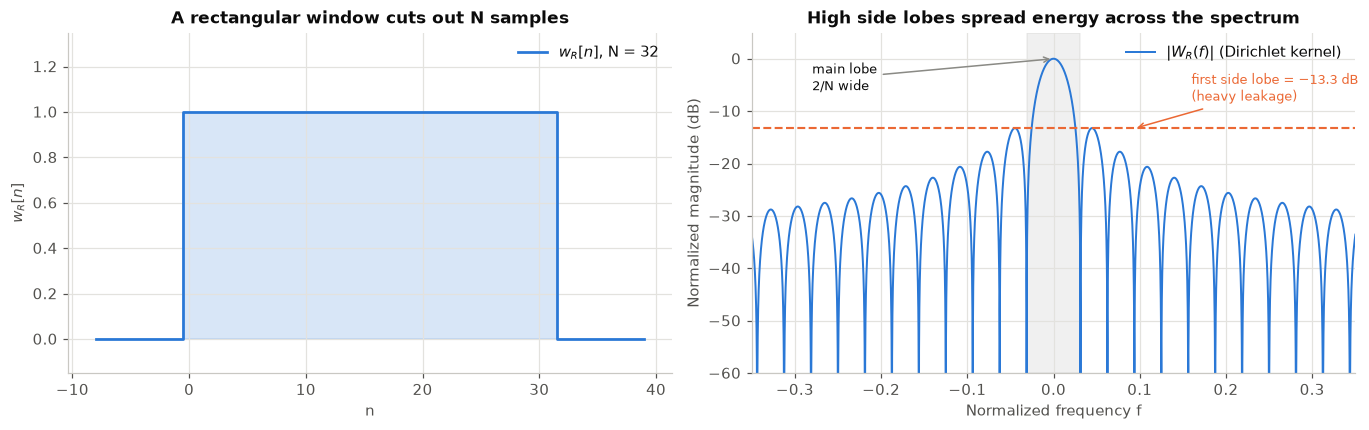

N = 32: main-lobe width (null-to-null) = 2/N = 0.0625
The rectangular window's side lobes fall by only 6 dB/octave, which is very slow


In [12]:
# ---- Anatomy of the rectangular window ----
N_w  = 32
f_w  = np.linspace(-0.5, 0.5, 8001)
W_R  = np.abs(np.sin(np.pi*f_w*N_w) / np.where(np.abs(np.sin(np.pi*f_w))<1e-12,
                                               1e-12, np.sin(np.pi*f_w)))
W_R[np.abs(f_w) < 1e-9] = N_w
W_dB = 20*np.log10(W_R/W_R.max() + 1e-16)

fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.0))

ax[0].step(np.arange(-8, N_w+8), np.where((np.arange(-8, N_w+8)>=0) &
           (np.arange(-8, N_w+8)<N_w), 1, 0), where="mid", color=C_PER, lw=1.8,
           label=f"$w_R[n]$, N = {N_w}")
ax[0].fill_between(np.arange(-8, N_w+8),
                   np.where((np.arange(-8, N_w+8)>=0) & (np.arange(-8, N_w+8)<N_w), 1, 0),
                   step="mid", color=C_PER, alpha=0.18)
ax[0].set_ylim(-0.15, 1.35); ax[0].set_xlabel("n"); ax[0].set_ylabel("$w_R[n]$")
ax[0].set_title("A rectangular window cuts out N samples")
ax[0].legend(loc="upper right")

ax[1].plot(f_w, W_dB, color=C_PER, lw=1.3, label="$|W_R(f)|$ (Dirichlet kernel)")
ax[1].axhline(-13.3, color=C_BAR, ls="--", lw=1.4)
ax[1].annotate("first side lobe = −13.3 dB\n(heavy leakage)", xy=(3/N_w, -13.3),
               xytext=(0.16, -8), color=C_BAR, fontsize=8.5,
               arrowprops=dict(arrowstyle="->", color=C_BAR, lw=1))
ax[1].annotate("main lobe\n2/N wide", xy=(0, 0), xytext=(-0.28, -6),
               color=C_TRUE, fontsize=8.5,
               arrowprops=dict(arrowstyle="->", color=C_MUTE, lw=1))
ax[1].axvspan(-1/N_w, 1/N_w, color=C_MUTE, alpha=0.12)
ax[1].set_xlim(-0.35, 0.35); ax[1].set_ylim(-60, 5)
ax[1].set_xlabel("Normalized frequency f"); ax[1].set_ylabel("Normalized magnitude (dB)")
ax[1].set_title("High side lobes spread energy across the spectrum")
ax[1].legend(loc="upper right")

plt.tight_layout(); plt.show()

print(f"N = {N_w}: main-lobe width (null-to-null) = 2/N = {2/N_w:.4f}")
print("The rectangular window's side lobes fall by only 6 dB/octave, which is very slow")

## 5.2 Leakage can hide a real signal

This experiment shows the damage leakage does.

The signal has two sines: a strong one at $f_1 = 0.20$ and one **60 dB weaker**, only 8 bins
away ($f_2 = f_1 + 8/N$).

In terms of resolution the second sine is *easy* to separate from the first: they are 8 bins
apart and the main lobe is only 2 bins wide. Even so, **leakage** from the first sine buries it.
That is a separate problem from resolution.

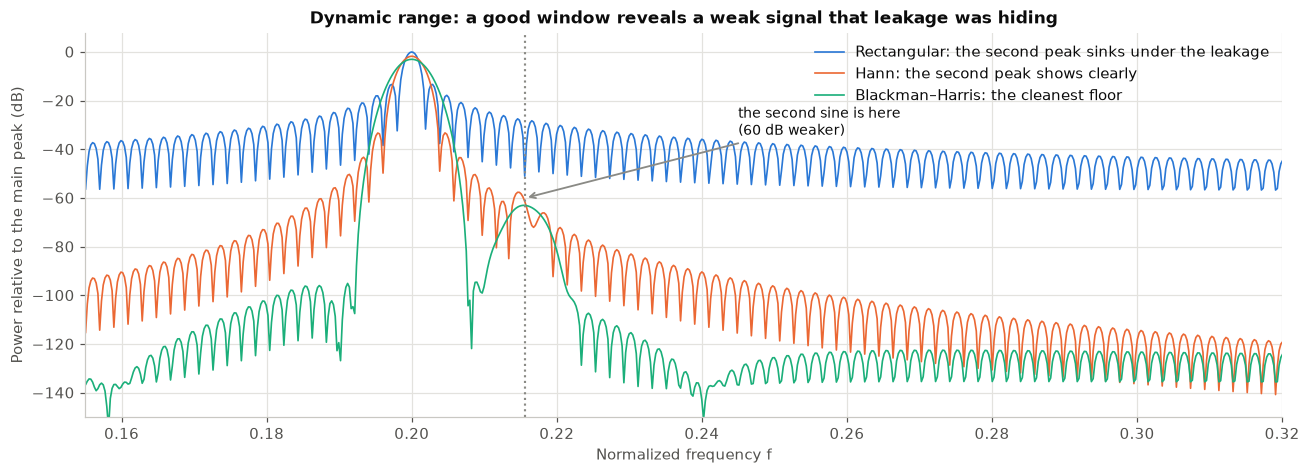

     Rectangular: 2nd peak =   -51.0 dB | leakage floor =    -41.0 dB | above floor  -10.0 dB  → hidden
            Hann: 2nd peak =   -61.3 dB | leakage floor =   -101.5 dB | above floor   40.2 dB  → visible
 Blackman–Harris: 2nd peak =   -63.0 dB | leakage floor =   -127.7 dB | above floor   64.7 dB  → visible


In [13]:
# ---- Leakage buries a weak signal ----
N_lk = 512
n_lk = np.arange(N_lk)
f1_lk  = 0.20
f2_lk  = f1_lk + 8/N_lk                 # 8 bins away, far enough for resolution
A2 = 10**(-60/20)                       # 60 dB weaker
x_lk = np.sin(2*np.pi*f1_lk*n_lk) + A2*np.sin(2*np.pi*f2_lk*n_lk)

NFFT_lk = 4096
f_lk = np.fft.rfftfreq(NFFT_lk)

def per_win(x, w, NFFT):
    """Periodogram with window w, power-normalized by U = mean(w²)."""
    U = np.mean(w**2)
    return np.abs(np.fft.rfft(x*w, NFFT))**2 / (len(x)*U)

P_rect = per_win(x_lk, np.ones(N_lk),                 NFFT_lk)
P_hann = per_win(x_lk, sig.windows.hann(N_lk, sym=False), NFFT_lk)
P_blk  = per_win(x_lk, sig.windows.blackmanharris(N_lk, sym=False), NFFT_lk)

ref = P_rect.max()
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.plot(f_lk, 10*np.log10(P_rect/ref + 1e-20), color=C_PER, lw=1.1,
        label="Rectangular: the second peak sinks under the leakage")
ax.plot(f_lk, 10*np.log10(P_hann/ref + 1e-20), color=C_BAR, lw=1.1,
        label="Hann: the second peak shows clearly")
ax.plot(f_lk, 10*np.log10(P_blk/ref  + 1e-20), color=C_WEL, lw=1.1,
        label="Blackman–Harris: the cleanest floor")
ax.axvline(f2_lk, color=C_MUTE, ls=":", lw=1.4)
ax.annotate("the second sine is here\n(60 dB weaker)", xy=(f2_lk, -60),
            xytext=(0.245, -34), color=C_TRUE, fontsize=9,
            arrowprops=dict(arrowstyle="->", color=C_MUTE, lw=1.2))
ax.set_xlim(0.155, 0.32); ax.set_ylim(-150, 8)
ax.set_xlabel("Normalized frequency f"); ax.set_ylabel("Power relative to the main peak (dB)")
ax.set_title("Dynamic range: a good window reveals a weak signal that leakage was hiding")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

# Measure how far each window lifts the second peak above the nearby leakage floor
# (a peak is visible only if it rises above the leakage floor around it)
near = (f_lk > f2_lk + 0.01) & (f_lk < f2_lk + 0.06)
for nm, P in [("Rectangular", P_rect), ("Hann", P_hann), ("Blackman–Harris", P_blk)]:
    k2   = np.argmin(np.abs(f_lk - f2_lk))
    peak = 10*np.log10(P[k2]/ref)
    side = 10*np.log10(np.median(P[near])/ref)
    verdict = "hidden" if peak - side < 6 else "visible"
    print(f"{nm:>16s}: 2nd peak = {peak:7.1f} dB | leakage floor = {side:8.1f} dB "
          f"| above floor {peak-side:6.1f} dB  → {verdict}")

With the rectangular window the second peak sits **below** the leakage floor around it (the value
is negative), so it is invisible even when you know where to look. With Hann it rises about 40 dB
above the floor, and Blackman–Harris gives the cleanest floor. The data is identical in all three
cases; only the window changes.

This is **not** a resolution problem: the peaks are 8 bins apart and the main lobe is 2 bins
wide, so a larger $N$ or more zero-padding would not help. The problem is entirely in the
*side lobes*, and only a different window fixes it.

## 5.3 The trade-off between resolution and dynamic range

A better window has a price:

$$\text{low side lobes (good dynamic range)} \;\Longleftrightarrow\; \text{wide main lobe (poor resolution)}$$

Lower side lobes come from tapering the window toward its edges, which shortens the part of the
data that effectively counts.

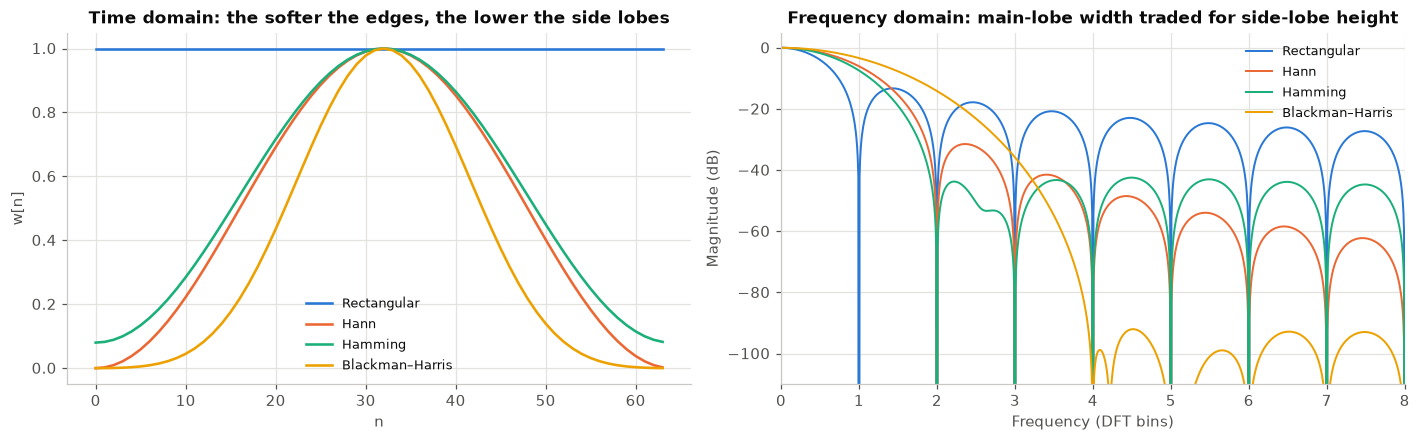

Window                     Peak side lobe      −3 dB width     ENBW
--------------------------------------------------------------------
Rectangular                      -13.3 dB          0.89 bin   1.000
Hann                             -31.5 dB          1.44 bin   1.500
Hamming                          -42.4 dB          1.30 bin   1.363
Blackman–Harris                  -92.0 dB          1.91 bin   2.004

Down the table: lower side lobes (better), wider main lobe (worse)


In [14]:
# ---- Four standard windows compared ----
L_w   = 64
wins  = {
    "Rectangular": (np.ones(L_w),                              C_PER),
    "Hann":                     (sig.windows.hann(L_w, sym=False),          C_BAR),
    "Hamming":                  (sig.windows.hamming(L_w, sym=False),       C_WEL),
    "Blackman–Harris":          (sig.windows.blackmanharris(L_w, sym=False), C_ALT),
}
NF_w = 8192

fig, ax = plt.subplots(1, 2, figsize=(13, 4.1))
rows = []
for nm, (w, col) in wins.items():
    ax[0].plot(np.arange(L_w), w, color=col, lw=1.7, label=nm)

    W  = np.abs(np.fft.rfft(w, NF_w)); W /= W.max()
    fW = np.fft.rfftfreq(NF_w)*L_w                 # axis in DFT bins
    ax[1].plot(fW, 20*np.log10(W + 1e-20), color=col, lw=1.3, label=nm)

    # measure the numbers
    WdB   = 20*np.log10(W + 1e-20)
    mn    = np.where(np.diff(np.sign(np.diff(WdB))) > 0)[0]      # first null
    first = mn[0] if len(mn) else 0
    psl   = WdB[first:].max()                                     # highest side lobe
    hpbw  = 2*fW[np.argmin(np.abs(WdB[:200] + 3.01))]             # -3 dB width
    enbw  = L_w*np.sum(w**2)/np.sum(w)**2                         # ENBW (bins)
    rows.append((nm, psl, hpbw, enbw))

ax[0].set_xlabel("n"); ax[0].set_ylabel("w[n]")
ax[0].set_title("Time domain: the softer the edges, the lower the side lobes")
ax[0].legend(loc="lower center", fontsize=8.5)

ax[1].set_xlim(0, 8); ax[1].set_ylim(-110, 5)
ax[1].set_xlabel("Frequency (DFT bins)"); ax[1].set_ylabel("Magnitude (dB)")
ax[1].set_title("Frequency domain: main-lobe width traded for side-lobe height")
ax[1].legend(loc="upper right", fontsize=8.5)
plt.tight_layout(); plt.show()

print(f"{'Window':<26s} {'Peak side lobe':>14s} {'−3 dB width':>16s} {'ENBW':>8s}")
print("-"*68)
for nm, psl, hpbw, enbw in rows:
    print(f"{nm:<26s} {psl:>11.1f} dB {hpbw:>13.2f} bin {enbw:>7.3f}")
print("\nDown the table: lower side lobes (better), wider main lobe (worse)")

Going from rectangular to Blackman–Harris, the side lobes improve from $-13$ dB to $-92$ dB,
while the main lobe grows almost four times wider.

**ENBW** (equivalent noise bandwidth) sums up how many times worse a window makes the resolution.

### Which window to choose

| Situation | Choice |
|---|---|
| Separate two peaks that are very close and similar in strength | rectangular (narrowest main lobe) |
| Find a very weak signal next to a strong one | Blackman–Harris (lowest side lobes) |
| General use, no strong reason either way | **Hann**, a good balance and Welch's default |

Now the other side: a case where the rectangular window *wins*.

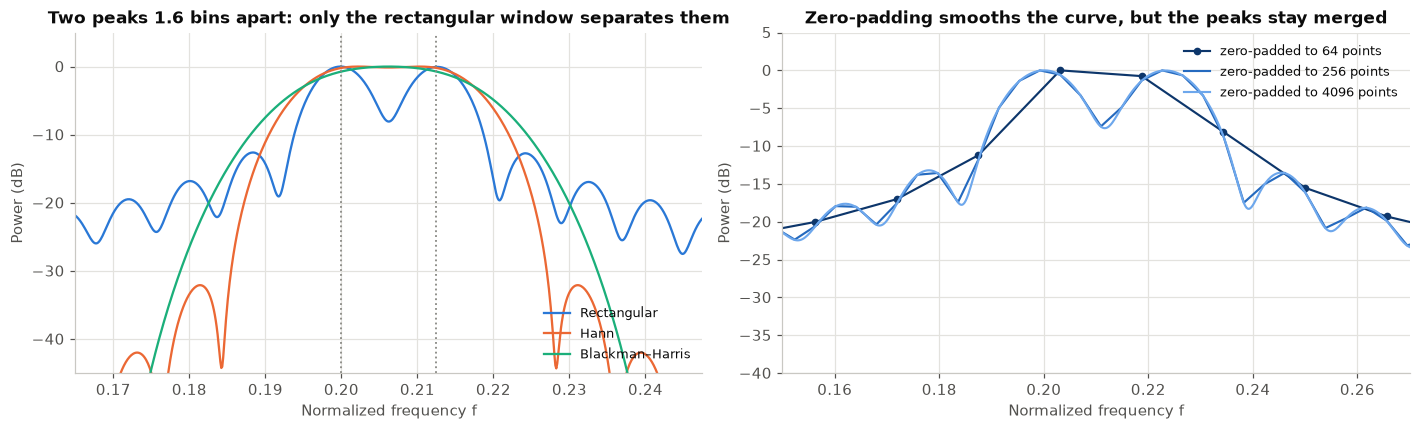

Two lessons:
  1. No window is best for everything: it depends on whether the task needs resolution or dynamic range
  2. Zero-padding is interpolation and adds no new data
     → the real resolution is set by the data length N alone (Δf ≈ 1/N)


In [15]:
# ---- The other side: two close peaks of equal strength → rectangular wins ----
N_r  = 128
n_r  = np.arange(N_r)
df   = 1.6/N_r                          # 1.6 bins apart, very close
fa, fb_ = 0.20, 0.20 + df
x_r  = np.sin(2*np.pi*fa*n_r) + np.sin(2*np.pi*fb_*n_r)

NF_r = 8192
f_r  = np.fft.rfftfreq(NF_r)
P_r_rect = per_win(x_r, np.ones(N_r),                              NF_r)
P_r_hann = per_win(x_r, sig.windows.hann(N_r, sym=False),          NF_r)
P_r_blk  = per_win(x_r, sig.windows.blackmanharris(N_r, sym=False), NF_r)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.0))

for P, col, nm in [(P_r_rect, C_PER, "Rectangular"), (P_r_hann, C_BAR, "Hann"),
                   (P_r_blk, C_WEL, "Blackman–Harris")]:
    ax[0].plot(f_r, 10*np.log10(P/P.max()+1e-20), color=col, lw=1.5, label=nm)
ax[0].axvline(fa,  color=C_MUTE, ls=":", lw=1.2)
ax[0].axvline(fb_, color=C_MUTE, ls=":", lw=1.2)
ax[0].set_xlim(fa-0.035, fb_+0.035); ax[0].set_ylim(-45, 5)
ax[0].set_xlabel("Normalized frequency f"); ax[0].set_ylabel("Power (dB)")
ax[0].set_title(f"Two peaks {df*N_r:.1f} bins apart: only the rectangular window separates them")
ax[0].legend(loc="lower right", fontsize=8.5)

# zero-padding does not help resolution
N_z = 64
n_z = np.arange(N_z)
x_z = np.sin(2*np.pi*0.20*n_z) + np.sin(2*np.pi*(0.20+1.5/N_z)*n_z)
for NFz, col, sty in [(N_z, BLUES[6], "-o"), (256, BLUES[4], "-"), (4096, BLUES[2], "-")]:
    Pz = np.abs(np.fft.rfft(x_z, NFz))**2 / N_z
    fz = np.fft.rfftfreq(NFz)
    ax[1].plot(fz, 10*np.log10(Pz/Pz.max()+1e-20), sty, color=col, lw=1.4, ms=4,
               label=f"zero-padded to {NFz} points")
ax[1].set_xlim(0.15, 0.27); ax[1].set_ylim(-40, 5)
ax[1].set_xlabel("Normalized frequency f"); ax[1].set_ylabel("Power (dB)")
ax[1].set_title("Zero-padding smooths the curve, but the peaks stay merged")
ax[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout(); plt.show()

print("Two lessons:")
print("  1. No window is best for everything: it depends on whether the task needs resolution or dynamic range")
print("  2. Zero-padding is interpolation and adds no new data")
print("     → the real resolution is set by the data length N alone (Δf ≈ 1/N)")

The right plot shows one of the most common misunderstandings in signal processing:
**zero-padding does not add resolution.** It draws the same curve with denser points, and two
peaks that have merged stay merged.

$$\text{real resolution} \approx \frac{1}{N} \quad(\text{set by the data length})
\qquad\ne\qquad
\text{frequency point spacing} = \frac{1}{N_{\text{FFT}}}$$

# Part 6. Bartlett's method (averaged periodogram)

## 6.1 The idea

Back to the main problem from Part 4: we need $E\{\cdot\}$ but have a single data set.

**M. S. Bartlett (1948)** proposed a direct solution:

> Split the $N$ samples into $K$ **non-overlapping** segments of $L = N/K$ samples each,
> compute the periodogram of each segment, and **average them**.

$$\boxed{\;\hat{S}_{B}(f) \;=\; \frac{1}{K}\sum_{i=0}^{K-1} \hat{S}^{(i)}(f),
\qquad
\hat{S}^{(i)}(f) = \frac{1}{L}\left|\sum_{n=0}^{L-1} x[iL+n]\,e^{-j2\pi f n}\right|^{2}\;}$$

It works because samples farther apart than the correlation length are nearly independent, so
the segments behave almost like $K$ separate realizations.

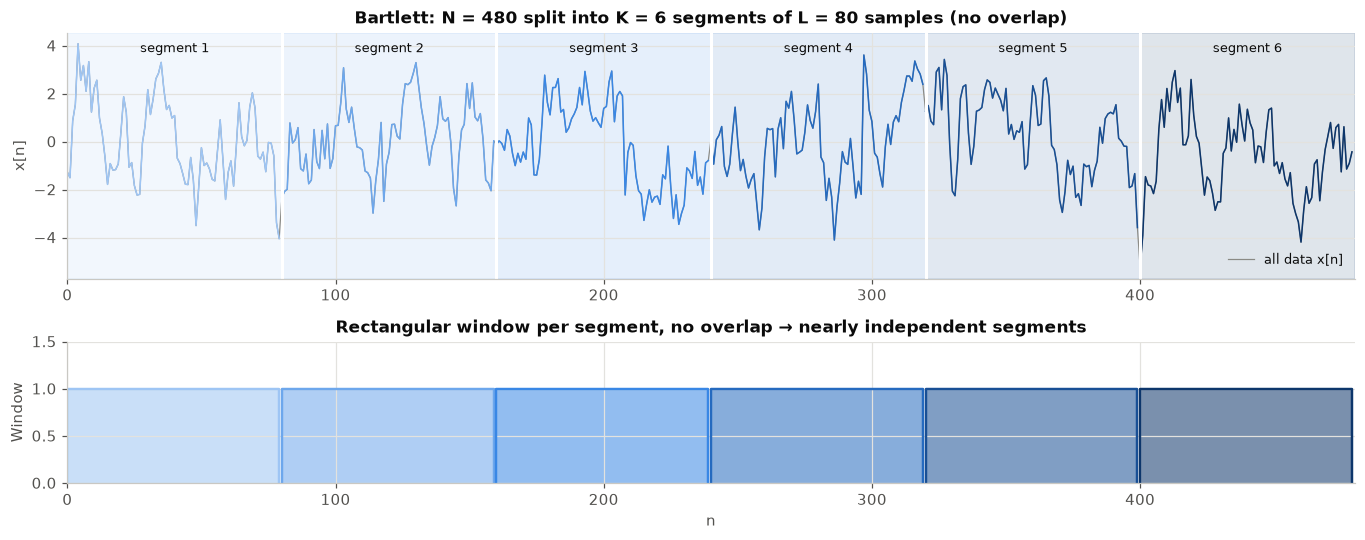

480 samples → 6 segments × 80 samples
Resolution goes from 1/N = 0.00208 to 1/L = 0.01250 (6× worse)


In [16]:
# ---- Diagram: how Bartlett splits the data ----
N_diag, K_diag = 480, 6
L_diag = N_diag // K_diag
x_diag = sig.lfilter([1.0], [1.0, -0.75], rng.standard_normal(N_diag+200))[200:]

fig, ax = plt.subplots(2, 1, figsize=(12.5, 5.0),
                       gridspec_kw={"height_ratios": [2, 1.15]})

ax[0].plot(np.arange(N_diag), x_diag, color=C_MUTE, lw=0.8, label="all data x[n]")
seg_cols = [BLUES[i % len(BLUES)] for i in [1,2,3,4,5,6]]
for i in range(K_diag):
    s, e = i*L_diag, (i+1)*L_diag
    ax[0].plot(np.arange(s, e), x_diag[s:e], color=seg_cols[i], lw=1.0)
    ax[0].axvspan(s, e, color=seg_cols[i], alpha=0.13)
    ax[0].text((s+e)/2, ax[0].get_ylim()[1]*0.82, f"segment {i+1}",
               ha="center", fontsize=8.5, color=C_TRUE)
for b in range(1, K_diag):
    ax[0].axvline(b*L_diag, color="white", lw=2.0)
ax[0].set_xlim(0, N_diag); ax[0].set_ylabel("x[n]")
ax[0].set_title(f"Bartlett: N = {N_diag} split into K = {K_diag} segments of L = {L_diag} samples (no overlap)")
ax[0].legend(loc="lower right", fontsize=8.5)

# Show each segment's rectangular window
for i in range(K_diag):
    s = i*L_diag
    ax[1].fill_between([s, s+L_diag-1], 0, 1, color=seg_cols[i], alpha=0.55,
                       step="pre", lw=0)
    ax[1].plot([s, s, s+L_diag-1, s+L_diag-1], [0, 1, 1, 0], color=seg_cols[i], lw=1.6)
ax[1].set_xlim(0, N_diag); ax[1].set_ylim(0, 1.5)
ax[1].set_xlabel("n"); ax[1].set_ylabel("Window")
ax[1].set_title("Rectangular window per segment, no overlap → nearly independent segments")

plt.tight_layout(); plt.show()
print(f"{N_diag} samples → {K_diag} segments × {L_diag} samples")
print(f"Resolution goes from 1/N = {1/N_diag:.5f} to 1/L = {1/L_diag:.5f} ({K_diag}× worse)")

## 6.2 Proof: the variance drops by a factor of $K$

**Assumption:** the $K$ segments are statistically independent. This is approximately true when
$L$ is much longer than the correlation length of the process.

The variance of a sum of independent random variables is the sum of their variances:

$$\operatorname{Var}\{\hat{S}_{B}(f)\}
= \operatorname{Var}\left\{\frac{1}{K}\sum_{i=0}^{K-1}\hat{S}^{(i)}(f)\right\}
\overset{\text{indep.}}{=} \frac{1}{K^{2}}\sum_{i=0}^{K-1}\operatorname{Var}\{\hat{S}^{(i)}(f)\}$$

Each segment is an ordinary periodogram, so $\operatorname{Var}\{\hat{S}^{(i)}\} \approx S^2(f)$
(from Part 4). Hence

$$\operatorname{Var}\{\hat{S}_{B}(f)\} = \frac{1}{K^{2}}\cdot K\cdot S^{2}(f)
\;=\; \boxed{\;\frac{S^{2}(f)}{K}\;} \qquad \blacksquare$$

**This estimator is consistent.** If $K \to \infty$ together with $N \to \infty$ (with
$L = N/K \to \infty$ as well), the variance goes to 0.

### The price

The expected value of Bartlett's estimate uses a Fejér kernel of length $L$, **not $N$**:

$$E\{\hat{S}_{B}(f)\} = S(f) \circledast W_{B}^{(L)}(f), \qquad
\text{main-lobe width} \approx \frac{2}{L} = \frac{2K}{N}$$

$$\boxed{\;\text{variance} \;\downarrow\; K \text{ times} \qquad\text{in exchange for}\qquad
\text{resolution} \;\uparrow\; K \text{ times (worse)}\;}$$

This is the basic trade-off of spectral estimation, and there is no way around it.

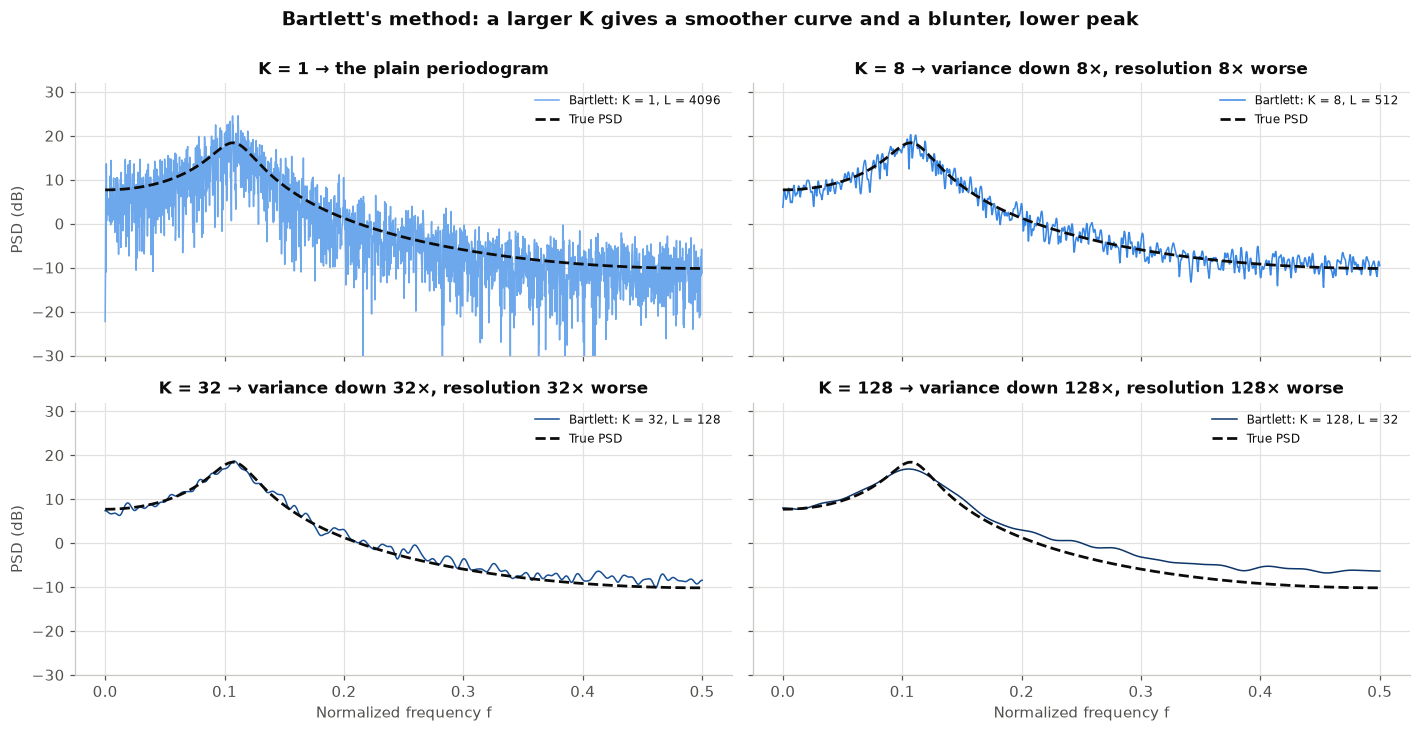

    K      L   Peak height (dB)   Std on flat floor (dB)
------------------------------------------------------------
    1   4096           24.61                  5.34
    8    512           20.31                  1.71
   32    128           18.72                  0.96
  128     32           16.90                  0.72

True peak height = 18.46 dB
→ large K: a much smoother curve (lower std), but the peak keeps dropping (more bias)


In [17]:
# ---- Bartlett in code ----
def bartlett_psd(x, L, NFFT=None):
    """
    Bartlett: split x into non-overlapping segments of length L and average their periodograms.
    Returns (freq, PSD, K) on the one-sided frequency grid 0…0.5, with fs = 1.
    """
    NFFT = NFFT or L
    # Guard: np.fft.rfft(seg, NFFT) with NFFT < L silently truncates the data
    # instead of zero-padding it, which gives a wrong result with no warning
    if NFFT < L:
        raise ValueError(f"need NFFT >= L (got NFFT={NFFT}, L={L}); "
                         "otherwise rfft truncates the data instead of zero-padding it")
    K = len(x) // L                       # drop the leftover partial segment
    if K == 0:
        raise ValueError("the data is shorter than one segment")
    segs = x[:K*L].reshape(K, L)
    P = np.abs(np.fft.rfft(segs, NFFT, axis=1))**2 / L
    return np.fft.rfftfreq(NFFT), P.mean(axis=0), K

# Test process: AR(2) with a sharp peak
a_test = np.array([1.0, -1.40, 0.81])
N_test = 4096
x_test = sig.lfilter([1.0], a_test, rng.standard_normal(N_test+1000))[1000:]
NF_bt   = 4096          # must be >= the largest L (K=1 → L=4096), or the data is truncated
f_t     = np.fft.rfftfreq(NF_bt)                      # the same grid used for plotting
_, H_t  = sig.freqz([1.0], a_test, worN=f_t, fs=1.0)
S_t     = np.abs(H_t)**2

fig, axes = plt.subplots(2, 2, figsize=(13, 6.6), sharex=True, sharey=True)
for axk, K_v, col in zip(axes.ravel(), [1, 8, 32, 128],
                         [BLUES[2], BLUES[3], BLUES[5], BLUES[6]]):
    L_v = N_test // K_v
    fB, PB, Kact = bartlett_psd(x_test, L_v, NFFT=NF_bt)
    axk.plot(fB, 10*np.log10(PB+1e-12), color=col, lw=1.0,
             label=f"Bartlett: K = {Kact}, L = {L_v}")
    axk.plot(f_t, 10*np.log10(S_t), "--", color=C_TRUE, lw=1.8, label="True PSD")
    ttl = "K = 1 → the plain periodogram" if K_v == 1 else \
          f"K = {K_v} → variance down {K_v}×, resolution {K_v}× worse"
    axk.set_title(ttl); axk.set_ylim(-30, 32)
    axk.legend(loc="upper right", fontsize=8)
axes[1,0].set_xlabel("Normalized frequency f"); axes[1,1].set_xlabel("Normalized frequency f")
axes[0,0].set_ylabel("PSD (dB)");       axes[1,0].set_ylabel("PSD (dB)")
fig.suptitle("Bartlett's method: a larger K gives a smoother curve and a blunter, lower peak",
             fontsize=12.5, fontweight="bold", y=1.00)
plt.tight_layout(); plt.show()

print(f"{'K':>5s} {'L':>6s} {'Peak height (dB)':>18s} {'Std on flat floor (dB)':>24s}")
print("-"*60)
for K_v in [1, 8, 32, 128]:
    L_v = N_test // K_v
    fB, PB, _ = bartlett_psd(x_test, L_v, NFFT=NF_bt)
    flat = (fB > 0.32) & (fB < 0.48)
    print(f"{K_v:>5d} {L_v:>6d} {10*np.log10(PB.max()):>15.2f} "
          f"{np.std(10*np.log10(PB[flat])):>21.2f}")
print(f"\nTrue peak height = {10*np.log10(S_t.max()):.2f} dB")
print("→ large K: a much smoother curve (lower std), but the peak keeps dropping (more bias)")

These plots show the whole trade-off, from $K=1$ (the raw periodogram, thick grass) to $K=128$
(very smooth, but the sharp peak flattened into a low hill).

The printed numbers confirm both sides: the `std` keeps falling (better), while the
`Peak height` keeps dropping away from the true value (worse).

Next, a Monte Carlo check of $\operatorname{Var} = S^2/K$.

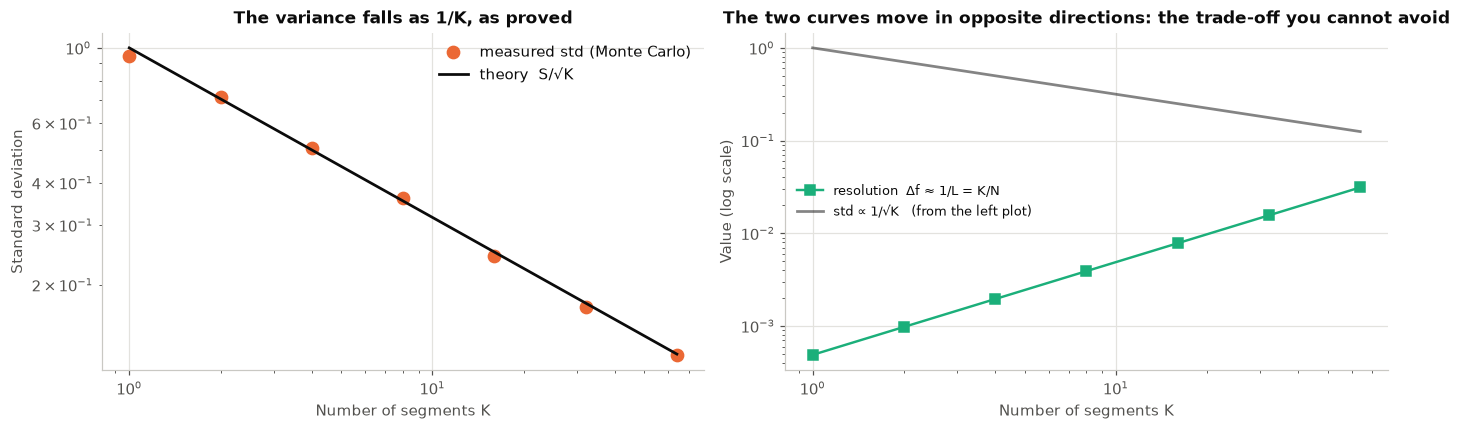

   K measured std   theory S/√K      error
---------------------------------------------
   1       0.9469        1.0000       5.3%
   2       0.7186        0.7071       1.6%
   4       0.5055        0.5000       1.1%
   8       0.3604        0.3536       1.9%
  16       0.2429        0.2500       2.8%
  32       0.1721        0.1768       2.6%
  64       0.1244        0.1250       0.5%


In [18]:
# ---- Check Var = S²/K with Monte Carlo ----
N_v2   = 2048
K_list = [1, 2, 4, 8, 16, 32, 64]
n_rep2 = 600
meas_std, theo_std = [], []

for K_v in K_list:
    L_v  = N_v2 // K_v
    vals = np.empty(n_rep2)
    for i in range(n_rep2):
        xw = rng.standard_normal(N_v2)            # white noise, S = 1
        _, PB, _ = bartlett_psd(xw, L_v, NFFT=L_v)
        vals[i] = PB[L_v//4]                      # look at f = 0.25
    meas_std.append(vals.std())
    theo_std.append(1.0/np.sqrt(K_v))             # S/√K with S = 1

fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.0))

ax[0].loglog(K_list, meas_std, "o", color=C_BAR, ms=8, label="measured std (Monte Carlo)")
ax[0].loglog(K_list, theo_std, "-", color=C_TRUE, lw=1.8, label="theory  S/√K")
ax[0].set_xlabel("Number of segments K"); ax[0].set_ylabel("Standard deviation")
ax[0].set_title("The variance falls as 1/K, as proved")
ax[0].legend(loc="upper right")

# The other side: resolution gets worse with K
ax[1].loglog(K_list, [K_v/N_v2 for K_v in K_list], "s-", color=C_WEL, ms=7,
             label="resolution  Δf ≈ 1/L = K/N")
ax[1].loglog(K_list, theo_std, "-", color=C_TRUE, lw=1.8, alpha=0.5,
             label="std ∝ 1/√K   (from the left plot)")
ax[1].set_xlabel("Number of segments K"); ax[1].set_ylabel("Value (log scale)")
ax[1].set_title("The two curves move in opposite directions: the trade-off you cannot avoid")
ax[1].legend(loc="center left", fontsize=8.5)

plt.tight_layout(); plt.show()

print(f"{'K':>4s} {'measured std':>12s} {'theory S/√K':>13s} {'error':>10s}")
print("-"*45)
for K_v, m, t in zip(K_list, meas_std, theo_std):
    print(f"{K_v:>4d} {m:>12.4f} {t:>13.4f} {abs(m-t)/t*100:>9.1f}%")

The measured values match the theory $S/\sqrt{K}$ to within a few percent. The rest is Monte Carlo
noise, plus the segments not being fully independent, so the proof holds.

### Where Bartlett falls short

Bartlett fixes the variance but leaves two problems:

1. **It still uses a rectangular window**, so all the leakage of Part 5 remains (side lobes at $-13$ dB)
2. **The segments do not overlap**, so the data near the boundaries is under-used, and a large $K$
   forces $L$ to be very short

Welch's method fixes both.

# Part 7. Welch's method

## 7.1 The idea

**Peter D. Welch (1967)** improved on Bartlett in two ways:

1. **A window on each segment**, which reduces leakage (Bartlett's first weakness)
2. **Overlapping segments**, typically by 50%, which gives more segments from the same data
   (the second weakness)

$$\boxed{\;\hat{S}_{W}(f) \;=\; \frac{1}{K}\sum_{i=0}^{K-1}
\frac{1}{L\,U}\left|\sum_{n=0}^{L-1} x[iD+n]\,w[n]\,e^{-j2\pi f n}\right|^{2}\;}$$

where

- $L$ is the segment length
- $D$ is the hop size; 50% overlap means $D = L/2$
- $K = \left\lfloor \frac{N-L}{D}\right\rfloor + 1$ is the number of segments
- $w[n]$ is the window (usually Hann)
- $U = \frac{1}{L}\sum_{n=0}^{L-1} w^{2}[n]$ is the **power correction factor**

## 7.2 Why $U$ is needed: proof of the normalization

The window shrinks the amplitude of the data, and without compensation the PSD comes out too low.
The right $U$ follows from requiring the estimator to be unbiased for white noise.

Let $x[n]$ be white noise with $E\{x[n]x^*[k]\} = \sigma^2\delta[n-k]$ and look at the numerator:

$$E\left\{\left|\sum_{n} x[n]w[n]e^{-j2\pi fn}\right|^{2}\right\}
= \sum_{n}\sum_{k} \underbrace{E\{x[n]x^{*}[k]\}}_{\sigma^{2}\delta[n-k]}\, w[n]w[k]\,e^{-j2\pi f(n-k)}$$

The delta keeps only the terms with $n = k$, where the exponential equals 1:

$$= \sigma^{2}\sum_{n=0}^{L-1} w^{2}[n]$$

We want the estimator to return exactly $\sigma^2$, the PSD of white noise, so we divide by
$\sum_n w^2[n]$:

$$\hat{S}_{W}(f) = \frac{\left|\cdot\right|^{2}}{\sum_{n} w^{2}[n]}
= \frac{\left|\cdot\right|^{2}}{L\cdot\underbrace{\tfrac{1}{L}\sum_{n} w^{2}[n]}_{U}} \qquad \blacksquare$$

> Dividing by $\sum w^2[n]$ gives a **PSD (power spectral density)**. For the **power spectrum**
> of a line spectrum, for example to read the amplitude of a sine, divide by
> $\left(\sum w[n]\right)^2$ instead. They are different quantities; in `scipy.signal.welch`
> they are `scaling='density'` and `scaling='spectrum'`.

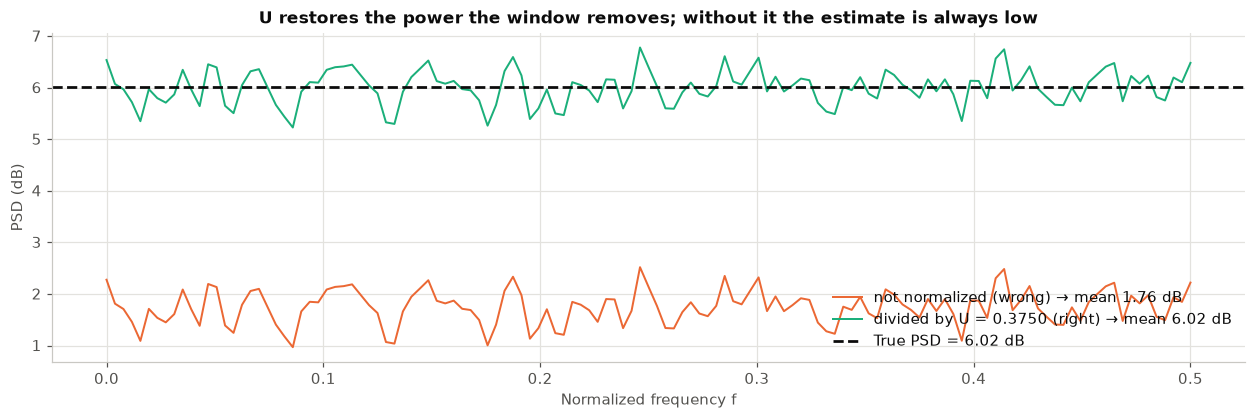

True σ²                      = 4.0000
Not normalized                 = 1.4984   ← off by -4.26 dB
Normalized by U             = 3.9958   ← correct

For Hann: U = mean(w²) = 3/8 = 0.3750 → forgetting it costs 4.26 dB


In [19]:
# ---- Welch in code ----
def welch_psd(x, L, overlap=0.5, window="hann", NFFT=None):
    """
    Welch's method. Returns (freq, two-sided PSD, number of segments K),
    evaluated at frequencies 0…0.5, with fs = 1.

    overlap : overlap fraction; 0.0 is Bartlett (with a rectangular window)
    """
    NFFT = NFFT or L
    # Same guard as bartlett_psd: NFFT < L makes rfft silently truncate the data,
    # which is worse here because the window gets cut off too
    if NFFT < L:
        raise ValueError(f"need NFFT >= L (got NFFT={NFFT}, L={L})")
    w    = sig.get_window(window, L, fftbins=True)
    D    = max(1, int(round(L * (1.0 - overlap))))    # hop size
    U    = np.mean(w**2)                              # normalization factor
    starts = range(0, len(x) - L + 1, D)
    P = np.array([np.abs(np.fft.rfft(x[s:s+L]*w, NFFT))**2 / (L*U)
                  for s in starts])
    return np.fft.rfftfreq(NFFT), P.mean(axis=0), len(P)

# ---- Show that U is needed: measure white noise of known power ----
sigma2_true = 4.0
x_u = np.sqrt(sigma2_true) * rng.standard_normal(20000)
L_u = 256
w_u = sig.windows.hann(L_u, sym=False)
U_u = np.mean(w_u**2)

D_u = L_u//2
segs = np.array([x_u[s:s+L_u] for s in range(0, len(x_u)-L_u+1, D_u)])
raw  = np.mean(np.abs(np.fft.rfft(segs*w_u, axis=1))**2, axis=0) / L_u

names = ["not normalized (wrong)", f"divided by U = {U_u:.4f} (right)"]
ests  = [raw, raw/U_u]

fig, ax = plt.subplots(figsize=(11.5, 3.9))
f_u = np.fft.rfftfreq(L_u)
for est, nm, col in zip(ests, names, [C_BAR, C_WEL]):
    ax.plot(f_u, 10*np.log10(est), color=col, lw=1.3,
            label=f"{nm} → mean {10*np.log10(est.mean()):.2f} dB")
ax.axhline(10*np.log10(sigma2_true), color=C_TRUE, ls="--", lw=1.8,
           label=f"True PSD = {10*np.log10(sigma2_true):.2f} dB")
ax.set_xlabel("Normalized frequency f"); ax.set_ylabel("PSD (dB)")
ax.set_title("U restores the power the window removes; without it the estimate is always low")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

print(f"True σ²                      = {sigma2_true:.4f}")
print(f"Not normalized                 = {raw.mean():.4f}   ← off by {10*np.log10(U_u):.2f} dB")
print(f"Normalized by U             = {(raw/U_u).mean():.4f}   ← correct")
print(f"\nFor Hann: U = mean(w²) = 3/8 = {3/8:.4f} → forgetting it costs {-10*np.log10(3/8):.2f} dB")

Without normalization the estimate is low by exactly 4.26 dB, which is $-10\log_{10}(3/8)$,
because the Hann window has $U = 3/8$ exactly.

## 7.3 Overlap and its effect on the variance

Overlap **adds segments** from the same data (almost twice as many at 50%), but
**overlapping segments are not independent**, so Bartlett's $\operatorname{Var} = S^2/K$
**does not apply directly.**

The general formula for the mean of correlated variables is

$$\operatorname{Var}\{\hat{S}_{W}\} = \frac{S^{2}}{K}
\left[1 + 2\sum_{j=1}^{K-1}\left(1-\frac{j}{K}\right)\rho[j]\right]$$

where $\rho[j]$ is the correlation coefficient between the periodograms of segments $j$ apart.
For Gaussian data it is the **square** of the correlation of the window:

$$\rho[j] \;=\; \left[\frac{\sum_{n} w[n]\,w[n+jD]}{\sum_{n} w^{2}[n]}\right]^{2}$$

(It is squared because the periodogram is the *square* of a Gaussian quantity.)

### The classic case: 50% overlap

With $D = L/2$, only neighbouring segments overlap ($\rho[j] = 0$ for $j \ge 2$), which leaves

$$\operatorname{Var}\{\hat{S}_{W}\} \approx \frac{S^{2}}{K}\left(1 + 2\rho[1]\right)$$

For a **triangular window**, $\rho[1] = (1/4)^2 = 1/16$, which gives

$$\operatorname{Var} = \frac{S^{2}}{K}\left(1+\tfrac{2}{16}\right) = \frac{9}{8}\cdot\frac{S^{2}}{K}$$

That is the well-known 9/8 from the textbooks. Because the overlap almost doubles $K$, the net
variance is $\frac{9}{8}\cdot\frac{1}{2} = \frac{9}{16} \approx 0.56$ times Bartlett's
**at the same resolution**, almost twice as good for the same data.

For **Hann**, $\rho[1] = (1/6)^2 = 1/36$, which gives a factor of $1 + 2/36 = 19/18 \approx 1.056$,
better still.

Now a numerical check of all this.

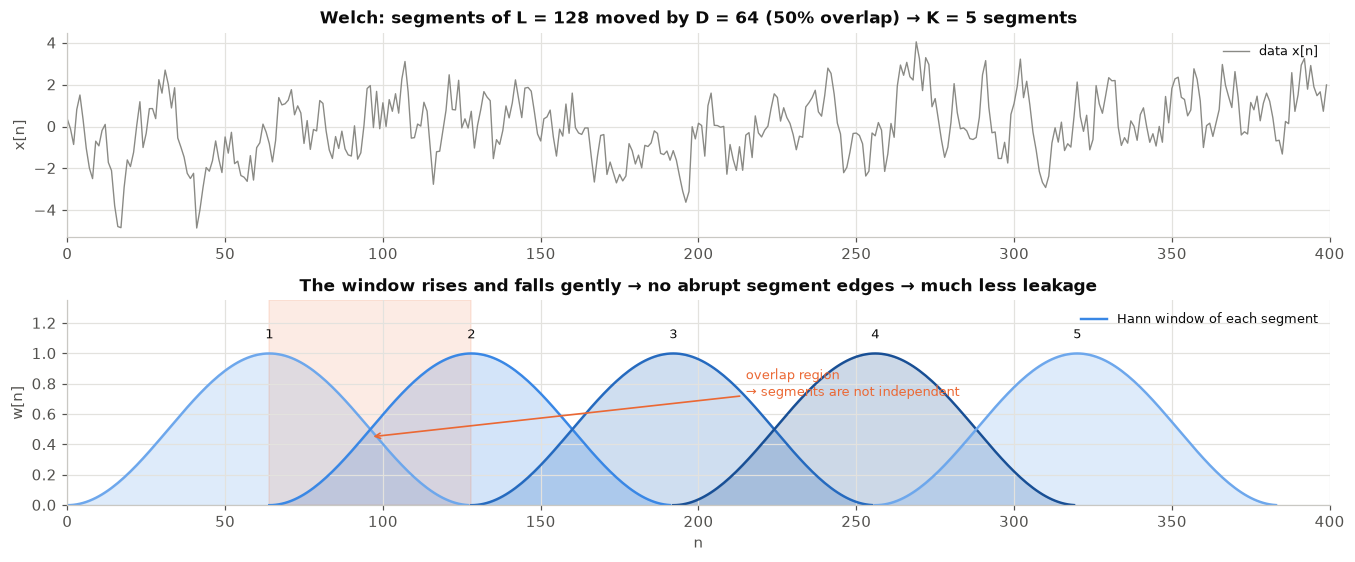

Bartlett (no overlap) : K = 3 segments
Welch (50% overlap)   : K = 5 segments  ← more segments from the same data


In [20]:
# ---- Diagram of the Welch overlap ----
N_ov, L_ov = 400, 128
D_ov = L_ov // 2
w_ov = sig.windows.hann(L_ov, sym=False)
x_ov = sig.lfilter([1.0], [1.0, -0.75], rng.standard_normal(N_ov+200))[200:]
starts_ov = list(range(0, N_ov-L_ov+1, D_ov))

fig, ax = plt.subplots(2, 1, figsize=(12.5, 5.2),
                       gridspec_kw={"height_ratios": [1.5, 1.5]})

ax[0].plot(np.arange(N_ov), x_ov, color=C_MUTE, lw=0.9, label="data x[n]")
ax[0].set_xlim(0, N_ov); ax[0].set_ylabel("x[n]")
ax[0].set_title(f"Welch: segments of L = {L_ov} moved by D = {D_ov} (50% overlap) → K = {len(starts_ov)} segments")
ax[0].legend(loc="upper right", fontsize=8.5)

for i, s in enumerate(starts_ov):
    col = BLUES[(i % 4) + 2]
    ax[1].plot(np.arange(s, s+L_ov), w_ov, color=col, lw=1.6)
    ax[1].fill_between(np.arange(s, s+L_ov), 0, w_ov, color=col, alpha=0.22)
    ax[1].text(s+L_ov/2, 1.10, f"{i+1}", ha="center", fontsize=8.5, color=C_TRUE)
ax[1].plot([], [], color=BLUES[3], lw=1.6, label="Hann window of each segment")
ax[1].axvspan(starts_ov[1], starts_ov[0]+L_ov, color=C_BAR, alpha=0.13)
ax[1].annotate("overlap region\n→ segments are not independent",
               xy=((starts_ov[1]+starts_ov[0]+L_ov)/2, 0.45), xytext=(215, 0.72),
               color=C_BAR, fontsize=8.5,
               arrowprops=dict(arrowstyle="->", color=C_BAR, lw=1.1))
ax[1].set_xlim(0, N_ov); ax[1].set_ylim(0, 1.35)
ax[1].set_xlabel("n"); ax[1].set_ylabel("w[n]")
ax[1].set_title("The window rises and falls gently → no abrupt segment edges → much less leakage")
ax[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout(); plt.show()

nb = N_ov // L_ov
print(f"Bartlett (no overlap) : K = {nb} segments")
print(f"Welch (50% overlap)   : K = {len(starts_ov)} segments  ← more segments from the same data")

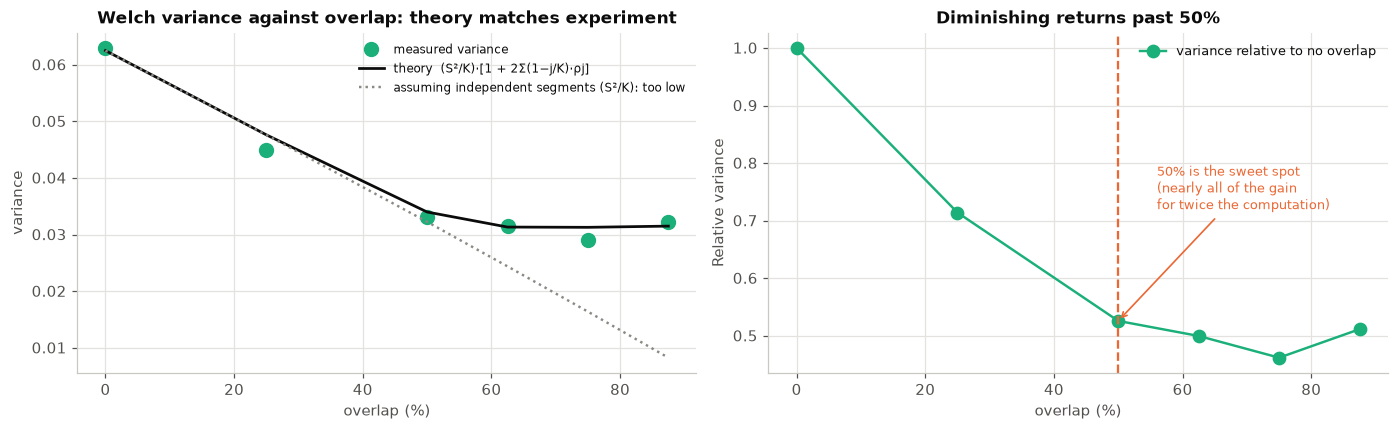

 overlap     K     ρ[1]   var meas.  var theory     error
--------------------------------------------------------------
    0.0%    16   0.0000     0.06296     0.06250      0.7%
   25.0%    21   0.0001     0.04496     0.04762      5.6%
   50.0%    31   0.0278     0.03311     0.03399      2.6%
   62.5%    41   0.1458     0.03146     0.03133      0.4%
   75.0%    61   0.4345     0.02909     0.03129      7.0%
   87.5%   121   0.8138     0.03220     0.03150      2.2%

Hann at 50% overlap: ρ[1] = 0.0278  (theory 1/36 = 0.0278)
Variance factor      = 1.0556  (theory 19/18 = 1.0556)


In [21]:
# ---- Check the Welch variance formula: theory vs Monte Carlo ----
def rho_theory(w, D, j):
    """Correlation between the periodograms of segments j apart (white Gaussian data)."""
    L = len(w)
    shift = j*D
    if shift >= L:
        return 0.0
    return (np.sum(w[shift:]*w[:L-shift]) / np.sum(w**2))**2

def var_factor(w, D, K):
    """The factor [1 + 2Σ(1-j/K)ρ[j]] in the variance formula."""
    return 1.0 + 2.0*sum((1-j/K)*rho_theory(w, D, j) for j in range(1, K))

N_wv  = 4096
L_wv  = 256
ovs   = [0.0, 0.25, 0.5, 0.625, 0.75, 0.875]
n_rep = 500
res   = []

for ov in ovs:
    w_  = sig.windows.hann(L_wv, sym=False)
    D_  = max(1, int(round(L_wv*(1-ov))))
    K_  = (N_wv - L_wv)//D_ + 1
    vals = np.empty(n_rep)
    for i in range(n_rep):
        xw = rng.standard_normal(N_wv)                    # white noise, S = 1
        _, PW, Kact = welch_psd(xw, L_wv, overlap=ov, window="hann", NFFT=L_wv)
        vals[i] = PW[L_wv//4]
    var_meas = vals.var()
    var_theo = (1.0/K_) * var_factor(w_, D_, K_)          # S = 1
    res.append((ov, K_, var_meas, var_theo, rho_theory(w_, D_, 1)))

fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.0))

ovp = [r[0]*100 for r in res]
ax[0].plot(ovp, [r[2] for r in res], "o", color=C_WEL, ms=9, label="measured variance")
ax[0].plot(ovp, [r[3] for r in res], "-", color=C_TRUE, lw=1.8,
           label="theory  (S²/K)·[1 + 2Σ(1−j/K)·ρj]")
ax[0].plot(ovp, [1.0/r[1] for r in res], ":", color=C_MUTE, lw=1.6,
           label="assuming independent segments (S²/K): too low")
ax[0].set_xlabel("overlap (%)"); ax[0].set_ylabel("variance")
ax[0].set_title("Welch variance against overlap: theory matches experiment")
ax[0].legend(loc="upper right", fontsize=8)

# Diminishing returns: variance relative to 0% overlap
base = res[0][2]
ax[1].plot(ovp, [r[2]/base for r in res], "o-", color=C_WEL, ms=8,
           label="variance relative to no overlap")
ax[1].axvline(50, color=C_BAR, ls="--", lw=1.5)
ax[1].annotate("50% is the sweet spot\n(nearly all of the gain\nfor twice the computation)",
               xy=(50, res[2][2]/base), xytext=(56, 0.72), color=C_BAR, fontsize=8.5,
               arrowprops=dict(arrowstyle="->", color=C_BAR, lw=1.1))
ax[1].set_xlabel("overlap (%)"); ax[1].set_ylabel("Relative variance")
ax[1].set_title("Diminishing returns past 50%")
ax[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout(); plt.show()

print(f"{'overlap':>8s} {'K':>5s} {'ρ[1]':>8s} {'var meas.':>11s} {'var theory':>11s} {'error':>9s}")
print("-"*62)
for ov, K_, vm, vt, r1 in res:
    print(f"{ov*100:>7.1f}% {K_:>5d} {r1:>8.4f} {vm:>11.5f} {vt:>11.5f} {abs(vm-vt)/vt*100:>8.1f}%")
print(f"\nHann at 50% overlap: ρ[1] = {res[2][4]:.4f}  (theory 1/36 = {1/36:.4f})")
print(f"Variance factor      = {1+2*res[2][4]:.4f}  (theory 19/18 = {19/18:.4f})")

Theory and experiment agree to within a few percent, and the computed $\rho[1] = 1/36$ and factor
$19/18$ match exactly.

The grey dotted line shows a common mistake: using $S^2/K$ directly for Welch
**underestimates the variance**, because it ignores that overlapping segments are not independent.

The right plot shows why **50% is the standard choice**: it gets almost all of the gain for twice
the computation. Going to 75% helps only a little more and doubles the computation again.

# Part 8. The three methods compared

## 8.1 By eye, on the same data

A fair comparison fixes the **segment length $L$**, because $L$ sets the resolution. With the same
$L$ all three have similar resolution, and we can see which gives the lower variance.

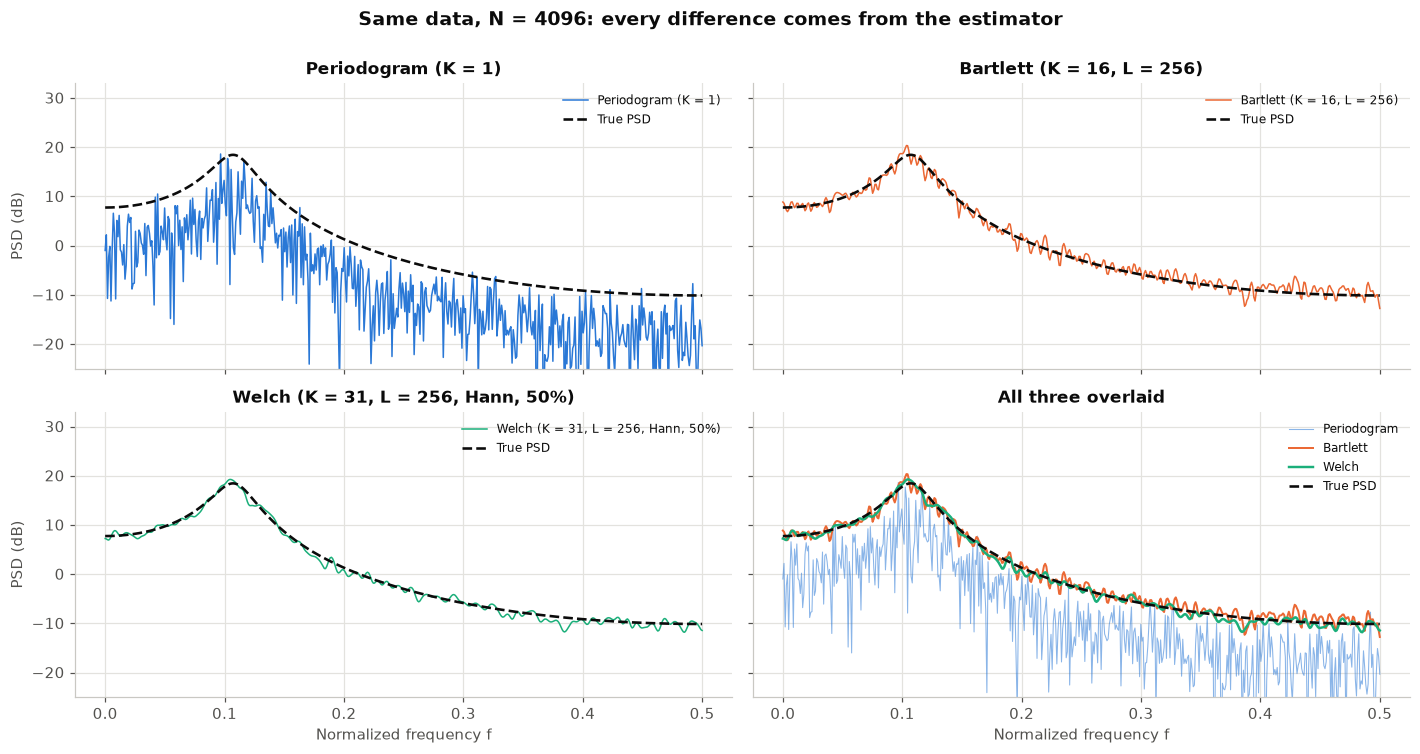

Method              K Std on flat floor    Error at peak
----------------------------------------------------------
Periodogram         1          6.34 dB          0.18 dB
Bartlett           16          1.27 dB          1.89 dB
Welch              31          0.97 dB          0.80 dB


In [22]:
# ---- The three methods on the same data ----
a_cmp  = np.array([1.0, -1.40, 0.81])          # AR(2) with a sharp peak
N_cmp  = 4096
L_cmp  = 256
NF_cmp = 1024
x_cmp  = sig.lfilter([1.0], a_cmp, rng.standard_normal(N_cmp+1000))[1000:]

f_cmp   = np.fft.rfftfreq(NF_cmp)
_, H_c  = sig.freqz([1.0], a_cmp, worN=f_cmp, fs=1.0)
S_cmp   = np.abs(H_c)**2

P_per          = np.abs(np.fft.rfft(x_cmp, NF_cmp))**2 / N_cmp
_, P_bart, Kb  = bartlett_psd(x_cmp, L_cmp, NFFT=NF_cmp)
_, P_wel,  Kw  = welch_psd(x_cmp, L_cmp, overlap=0.5, window="hann", NFFT=NF_cmp)

fig, ax = plt.subplots(2, 2, figsize=(13, 6.8), sharex=True, sharey=True)
panels = [(P_per,  C_PER, f"Periodogram (K = 1)"),
          (P_bart, C_BAR, f"Bartlett (K = {Kb}, L = {L_cmp})"),
          (P_wel,  C_WEL, f"Welch (K = {Kw}, L = {L_cmp}, Hann, 50%)")]

for axk, (P, col, nm) in zip(ax.ravel()[:3], panels):
    axk.plot(f_cmp, 10*np.log10(P+1e-12), color=col, lw=1.0, label=nm)
    axk.plot(f_cmp, 10*np.log10(S_cmp), "--", color=C_TRUE, lw=1.7, label="True PSD")
    axk.set_title(nm); axk.set_ylim(-25, 33)
    axk.legend(loc="upper right", fontsize=8)

axk = ax.ravel()[3]
axk.plot(f_cmp, 10*np.log10(P_per+1e-12),  color=C_PER, lw=0.7, alpha=0.55, label="Periodogram")
axk.plot(f_cmp, 10*np.log10(P_bart+1e-12), color=C_BAR, lw=1.3, label="Bartlett")
axk.plot(f_cmp, 10*np.log10(P_wel+1e-12),  color=C_WEL, lw=1.6, label="Welch")
axk.plot(f_cmp, 10*np.log10(S_cmp), "--", color=C_TRUE, lw=1.7, label="True PSD")
axk.set_title("All three overlaid"); axk.set_ylim(-25, 33)
axk.legend(loc="upper right", fontsize=8)

for k in [2, 3]: ax.ravel()[k].set_xlabel("Normalized frequency f")
for k in [0, 2]: ax.ravel()[k].set_ylabel("PSD (dB)")
fig.suptitle("Same data, N = 4096: every difference comes from the estimator",
             fontsize=12.5, fontweight="bold", y=1.00)
plt.tight_layout(); plt.show()

flat = (f_cmp > 0.33) & (f_cmp < 0.48)
print(f"{'Method':<16s} {'K':>4s} {'Std on flat floor':>16s} {'Error at peak':>16s}")
print("-"*58)
for P, nm, K_ in [(P_per, "Periodogram", 1), (P_bart, "Bartlett", Kb), (P_wel, "Welch", Kw)]:
    s = np.std(10*np.log10(P[flat]))
    e = 10*np.log10(P.max()) - 10*np.log10(S_cmp.max())
    print(f"{nm:<16s} {K_:>4d} {s:>13.2f} dB {e:>13.2f} dB")

The periodogram is thick grass, while Welch is smooth and follows the shape of the true PSD best,
from exactly the same data.

At the same $L$, Welch gets almost twice as many segments as Bartlett (from the overlap), so its
std is lower.

### Why the periodogram looks lower than the true PSD

In the top-left plot the periodogram's grass seems to sit *below* the dashed line, even though we
just proved it is (almost) unbiased.

This is not bias. It comes from **plotting in dB**:

- $E\{\hat{S}\} = S$ holds, but that is the mean on a **linear scale**
- The plot shows $10\log_{10}\hat{S}$, and since $\log$ is concave, Jensen's inequality gives
  $E\{\log \hat{S}\} < \log E\{\hat{S}\}$

The offset follows exactly from $\hat{S}/S \sim \text{Exp}(1)$, which has $E\{\ln X\} = -\gamma$,
where $\gamma \approx 0.5772$ is the Euler–Mascheroni constant:

$$E\{10\log_{10}\hat{S}\} - 10\log_{10}S
= \frac{10}{\ln 10}\,E\{\ln X\} = -\frac{10\gamma}{\ln 10} \approx -2.51\ \text{dB}$$

> **A periodogram plotted in dB sits about 2.5 dB below the true value on average,**
> even though it is exactly right on a linear scale.
>
> Averaging $K$ segments, as Bartlett and Welch do, narrows the distribution, the Jensen effect
> shrinks with it, and the curve settles back onto the true line, as the plots show.

For the mean of $K$ independent segments, the offset follows from the digamma function $\psi$:

$$\text{offset in dB} = \frac{10}{\ln 10}\Big(\psi(K) - \ln K\Big)
\;\xrightarrow[\;K \text{ large}\;]{}\; -\frac{2.171}{K}\ \text{dB}$$

| $K$ | 1 | 2 | 4 | 8 | 16 | 31 |
|---|---|---|---|---|---|---|
| offset (dB) | $-2.51$ | $-1.17$ | $-0.57$ | $-0.28$ | $-0.14$ | $-0.07$ |

At $K = 31$ (the value in the Welch plot above) only $-0.07$ dB is left, too small to see.

## 8.2 Measuring with Monte Carlo

To measure rather than eyeball, we compute **bias**, **variance** and **MSE**:

$$\text{MSE}(f) = \underbrace{\left(E\{\hat{S}(f)\} - S(f)\right)^{2}}_{\text{bias}^2}
\;+\; \underbrace{\operatorname{Var}\{\hat{S}(f)\}}_{\text{variance}}$$

MSE is the fairest measure because it combines both sides of the trade-off.

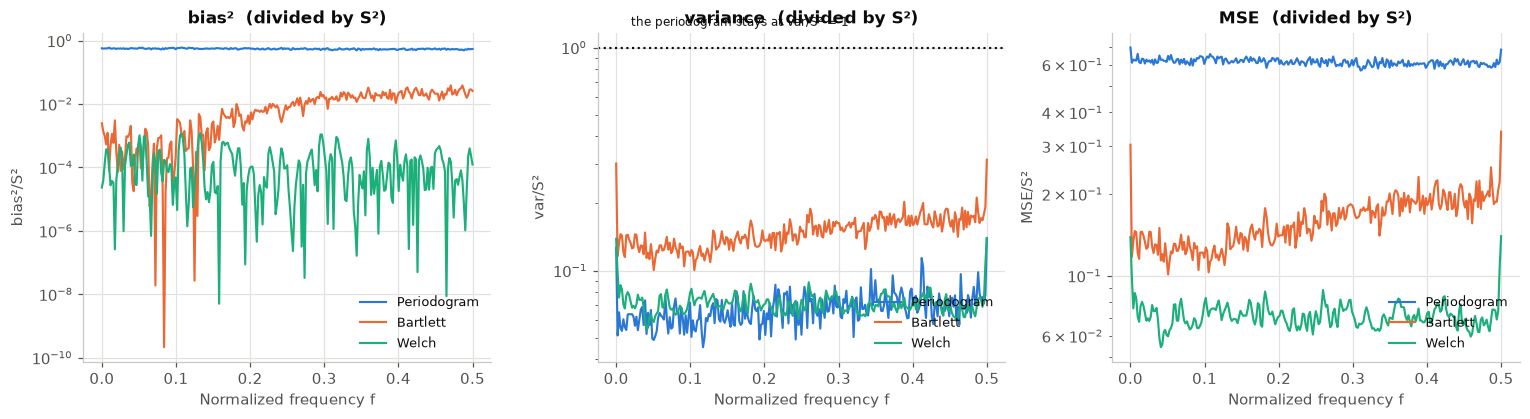

Method             mean bias²      mean var      mean MSE
----------------------------------------------------------
Periodogram           0.54646       0.06801       0.61447
Bartlett              0.01076       0.14994       0.16070
Welch                 0.00018       0.07157       0.07175

Lowest MSE: Welch


In [23]:
# ---- Monte Carlo: bias², variance and MSE of the three methods ----
n_mc2  = 400
N_mc   = 2048
L_mc   = 256
NF_mc  = 512
f_mc   = np.fft.rfftfreq(NF_mc)
_, H_m = sig.freqz([1.0], a_cmp, worN=f_mc, fs=1.0)
S_mc_true = np.abs(H_m)**2

acc = {k: [] for k in ["Periodogram", "Bartlett", "Welch"]}
for _ in range(n_mc2):
    xm = sig.lfilter([1.0], a_cmp, rng.standard_normal(N_mc+800))[800:]
    acc["Periodogram"].append(np.abs(np.fft.rfft(xm, NF_mc))**2 / N_mc)
    acc["Bartlett"].append(bartlett_psd(xm, L_mc, NFFT=NF_mc)[1])
    acc["Welch"].append(welch_psd(xm, L_mc, 0.5, "hann", NFFT=NF_mc)[1])

stats_tbl, cols = {}, {"Periodogram": C_PER, "Bartlett": C_BAR, "Welch": C_WEL}
for k, v in acc.items():
    A = np.array(v)
    bias2 = (A.mean(axis=0) - S_mc_true)**2
    var   = A.var(axis=0)
    stats_tbl[k] = (bias2, var, bias2 + var)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
for k in acc:
    b2, vr, mse = stats_tbl[k]
    ax[0].semilogy(f_mc, b2 / S_mc_true**2, color=cols[k], lw=1.4, label=k)
    ax[1].semilogy(f_mc, vr / S_mc_true**2, color=cols[k], lw=1.4, label=k)
    ax[2].semilogy(f_mc, mse / S_mc_true**2, color=cols[k], lw=1.4, label=k)

for axk, ttl, yl in zip(ax,
        ["bias²  (divided by S²)", "variance  (divided by S²)", "MSE  (divided by S²)"],
        ["bias²/S²", "var/S²", "MSE/S²"]):
    axk.set_xlabel("Normalized frequency f"); axk.set_ylabel(yl)
    axk.set_title(ttl); axk.legend(loc="lower right", fontsize=8.5)

ax[1].axhline(1.0, color=C_TRUE, ls=":", lw=1.4)
ax[1].text(0.02, 1.25, "the periodogram stays at var/S² = 1", fontsize=8, color=C_TRUE)
plt.tight_layout(); plt.show()

print(f"{'Method':<14s} {'mean bias²':>14s} {'mean var':>13s} {'mean MSE':>13s}")
print("-"*58)
for k in ["Periodogram", "Bartlett", "Welch"]:
    b2, vr, mse = [np.mean(z/S_mc_true**2) for z in stats_tbl[k]]
    print(f"{k:<14s} {b2:>14.5f} {vr:>13.5f} {mse:>13.5f}")
best = min(stats_tbl, key=lambda k: np.mean(stats_tbl[k][2]/S_mc_true**2))
print(f"\nLowest MSE: {best}")

From the printed table:

- bias²: the periodogram wins, because it uses all $N$ samples and blurs least; Bartlett and
  Welch do worse because their segments are short
- variance: the periodogram loses badly and stays at $\text{var}/S^2 = 1$, as proved
- MSE: Welch wins, because the large drop in variance outweighs the small rise in bias

## 8.3 Choosing the segment length $L$

$L$ is Welch's main control, and it sets the trade-off directly:

$$L \uparrow \;\Rightarrow\; \text{better resolution},\; K \downarrow \;\Rightarrow\; \text{worse variance}$$

There is a best $L$, found by minimizing the MSE.

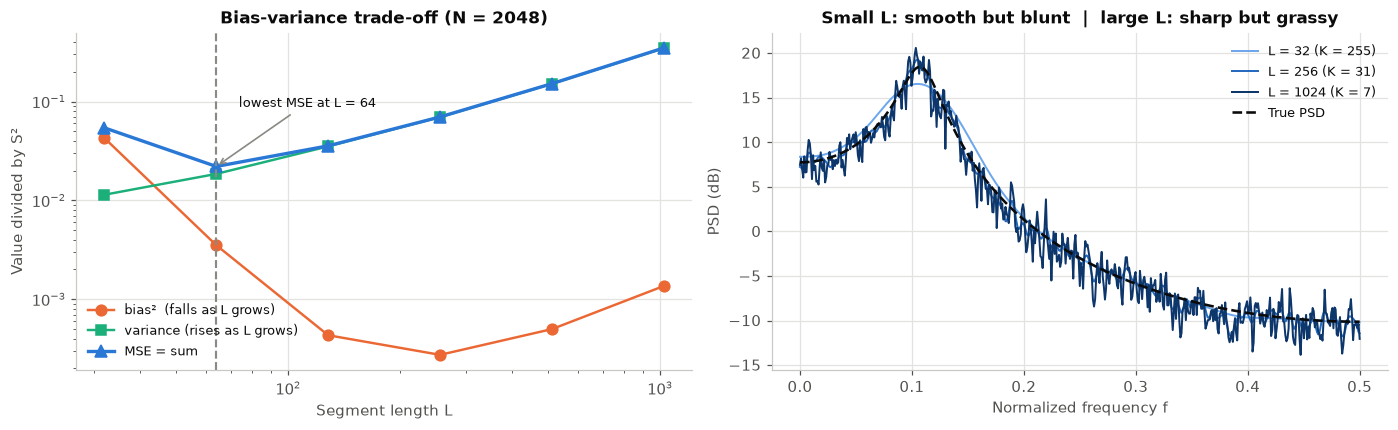

     L     K       bias²    variance         MSE
--------------------------------------------------
    32   127     0.04283     0.01140     0.05423
    64    63     0.00352     0.01852     0.02205  ← best
   128    31     0.00043     0.03520     0.03563
   256    15     0.00027     0.06965     0.06992
   512     7     0.00050     0.15144     0.15194
  1024     3     0.00136     0.34805     0.34941


In [24]:
# ---- Finding the best L: the MSE curve ----
L_grid = [32, 64, 128, 256, 512, 1024]
n_mc3  = 250
NF3    = 1024          # must be >= the largest L in L_grid
f3     = np.fft.rfftfreq(NF3)
_, H3  = sig.freqz([1.0], a_cmp, worN=f3, fs=1.0)
S3     = np.abs(H3)**2

curve = []
for L_v in L_grid:
    A = np.array([welch_psd(
            sig.lfilter([1.0], a_cmp, rng.standard_normal(N_mc+800))[800:],
            L_v, 0.5, "hann", NFFT=NF3)[1] for _ in range(n_mc3)])
    b2  = np.mean((A.mean(axis=0) - S3)**2 / S3**2)
    vr  = np.mean(A.var(axis=0) / S3**2)
    curve.append((L_v, b2, vr, b2+vr))

fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.0))

Ls   = [c[0] for c in curve]
ax[0].loglog(Ls, [c[1] for c in curve], "o-", color=C_BAR, ms=7, label="bias²  (falls as L grows)")
ax[0].loglog(Ls, [c[2] for c in curve], "s-", color=C_WEL, ms=7, label="variance (rises as L grows)")
ax[0].loglog(Ls, [c[3] for c in curve], "^-", color=C_PER, ms=8, lw=2.2, label="MSE = sum")
best_L = min(curve, key=lambda c: c[3])[0]
ax[0].axvline(best_L, color=C_MUTE, ls="--", lw=1.4)
ax[0].annotate(f"lowest MSE at L = {best_L}", xy=(best_L, min(c[3] for c in curve)),
               xytext=(best_L*1.15, min(c[3] for c in curve)*4), color=C_TRUE, fontsize=8.5,
               arrowprops=dict(arrowstyle="->", color=C_MUTE, lw=1.1))
ax[0].set_xlabel("Segment length L"); ax[0].set_ylabel("Value divided by S²")
ax[0].set_title(f"Bias-variance trade-off (N = {N_mc})")
ax[0].legend(loc="lower left", fontsize=8.5)

for L_v, col in zip([32, 256, 1024], [BLUES[2], BLUES[4], BLUES[6]]):
    _, Pv, Kv = welch_psd(x_cmp, L_v, 0.5, "hann", NFFT=1024)
    fv = np.fft.rfftfreq(1024)
    ax[1].plot(fv, 10*np.log10(Pv+1e-12), color=col, lw=1.3, label=f"L = {L_v} (K = {Kv})")
ax[1].plot(f_cmp, 10*np.log10(S_cmp), "--", color=C_TRUE, lw=1.7, label="True PSD")
ax[1].set_xlabel("Normalized frequency f"); ax[1].set_ylabel("PSD (dB)")
ax[1].set_title("Small L: smooth but blunt  |  large L: sharp but grassy")
ax[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout(); plt.show()

print(f"{'L':>6s} {'K':>5s} {'bias²':>11s} {'variance':>11s} {'MSE':>11s}")
print("-"*50)
for L_v, b2, vr, mse in curve:
    K_v = (N_mc - L_v)//(L_v//2) + 1
    mark = "  ← best" if L_v == best_L else ""
    print(f"{L_v:>6d} {K_v:>5d} {b2:>11.5f} {vr:>11.5f} {mse:>11.5f}{mark}")

The MSE curve has the classic U shape with a clear minimum, which is numerical evidence that
**a best $L$ exists.**

*(The minimum depends on the shape of the true PSD. A spectrum with sharper peaks needs a larger $L$.)*

## 8.4 A practical case: detecting a narrow resonance in noise

The task: is a **narrowband resonance** (a machine vibration, say, or narrowband interference)
hidden in the background noise?

### What to measure

A common mistake is to judge a peak by how many dB it stands above the floor. A peak is only
trustworthy if it rises higher than the **floor's own fluctuations** could reach by chance, so
the right measure is a standard score:

$$z \;=\; \frac{\text{peak height above the floor (dB)}}{\text{standard deviation of the floor (dB)}}$$

- **Periodogram:** the floor fluctuates by about $5.6$ dB (as proved in Part 4), so the
  denominator is large and $z$ is low
- **Welch** ($K$ segments): the floor fluctuates by about $5.6/\sqrt{K}$ dB, so the denominator is
  much smaller and $z$ is high

> Welch does not win every time. If the target is a **pure sine**, a long FFT (the periodogram)
> concentrates the energy of the sine in one bin and gives a *taller* peak, so the periodogram may
> even win. Welch is clearly better when the target is a **narrowband random signal** with a width
> of its own: resolution finer than that width does not help, and a steadier floor helps a lot.
> That is also the case where the *PSD* is the right description in the first place.

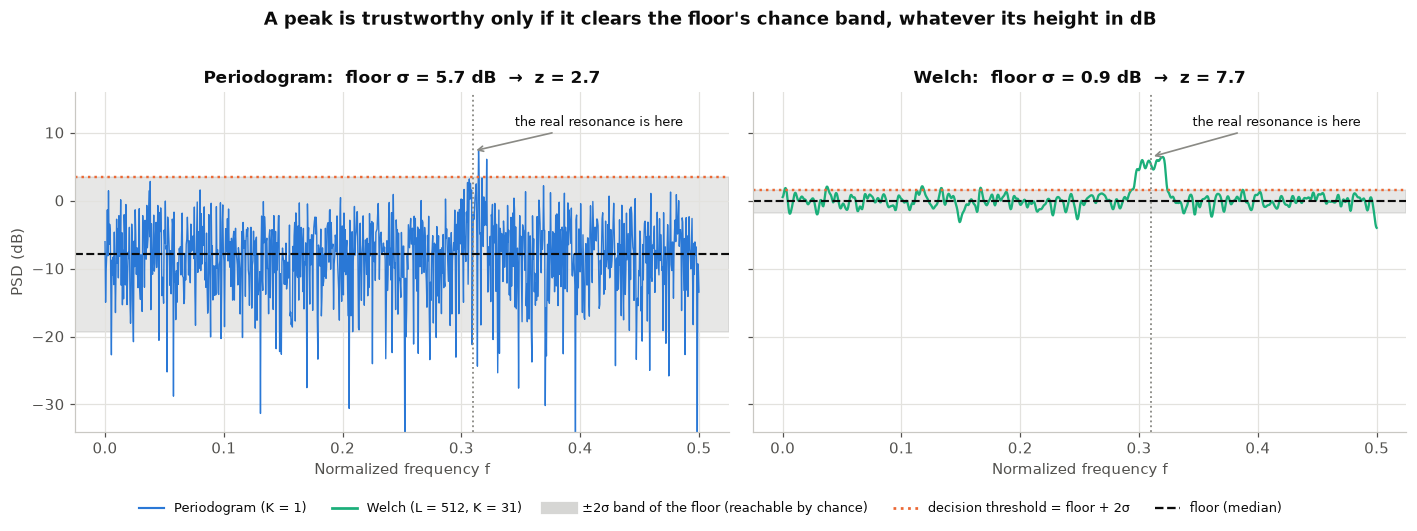

Method                   Peak above floor      Floor σ       z
--------------------------------------------------------------
Periodogram (K = 1)             15.2 dB       5.7 dB     2.7
Welch (L = 512, K = 31)          6.5 dB       0.9 dB     7.7

Welch gives a z 2.9× higher
Floor σ: periodogram = 5.7 dB (theory 5.57) | Welch = 0.9 dB (theory 5.57/√31 = 1.0)
→ the periodogram peak is higher in dB, but its floor jumps around just as much


In [25]:
# ---- In practice: detecting a narrowband resonance in noise ----
N_d  = 8192
f0_d = 0.31                                   # resonance frequency

# Make a narrowband random signal by passing white noise through a narrow band-pass filter
# (careful: butter takes Wn as a fraction of Nyquist; fs=1.0 lets us give it in cycles/sample)
bp_d  = sig.butter(6, [f0_d-0.012, f0_d+0.012], btype="band", output="sos", fs=1.0)
res_d = sig.sosfilt(bp_d, rng.standard_normal(N_d+3000))[3000:]
res_d *= 0.35 / np.sqrt(np.mean(res_d**2))    # make it weak
x_d   = res_d + rng.standard_normal(N_d)      # + white background noise (flat PSD = 1)

NF_d = 2048
f_d  = np.fft.rfftfreq(NF_d)
P_d_per       = np.abs(np.fft.rfft(x_d, NF_d))**2 / N_d
_, P_d_w, K_d = welch_psd(x_d, 512, 0.5, "hann", NFFT=NF_d)

# Signal-free bands, used to measure the floor and how much it fluctuates
off_d  = ((f_d > 0.05) & (f_d < 0.26)) | ((f_d > 0.37) & (f_d < 0.47))
band_d = (f_d > 0.29) & (f_d < 0.33)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
rows_d = []
for axk, P, col, nm in [(ax[0], P_d_per, C_PER, "Periodogram (K = 1)"),
                        (ax[1], P_d_w,   C_WEL, f"Welch (L = 512, K = {K_d})")]:
    PdB   = 10*np.log10(P + 1e-12)
    floor = np.median(PdB[off_d])
    sd    = np.std(PdB[off_d])
    peak  = PdB[band_d].max()
    z     = (peak - floor) / sd
    rows_d.append((nm, peak-floor, sd, z))

    axk.plot(f_d, PdB, color=col, lw=0.9 if "Period" in nm else 1.5, label=nm)
    # ±2σ band of the floor: the level chance alone can reach
    axk.axhspan(floor-2*sd, floor+2*sd, color=C_MUTE, alpha=0.20)
    axk.axhline(floor, color=C_TRUE, ls="--", lw=1.4)
    axk.axhline(floor+2*sd, color=C_BAR, ls=":", lw=1.6)
    axk.axvline(f0_d, color=C_MUTE, ls=":", lw=1.2)
    axk.annotate("the real resonance is here", xy=(f0_d, peak), xytext=(0.345, 11),
                 color=C_TRUE, fontsize=8.5,
                 arrowprops=dict(arrowstyle="->", color=C_MUTE, lw=1.1))
    axk.set_title(f"{nm.split(' (')[0]}:  floor σ = {sd:.1f} dB  →  z = {z:.1f}")
    axk.set_xlabel("Normalized frequency f")
    axk.set_ylim(-34, 16)
ax[0].set_ylabel("PSD (dB)")

# One shared legend below the figure, so it does not cover the data or the threshold lines
handles = [plt.Line2D([], [], color=C_PER, lw=1.4),
           plt.Line2D([], [], color=C_WEL, lw=1.8),
           plt.Line2D([], [], color=C_MUTE, lw=8, alpha=0.35),
           plt.Line2D([], [], color=C_BAR, ls=":", lw=1.8),
           plt.Line2D([], [], color=C_TRUE, ls="--", lw=1.5)]
labels  = ["Periodogram (K = 1)", f"Welch (L = 512, K = {K_d})",
           "±2σ band of the floor (reachable by chance)",
           "decision threshold = floor + 2σ", "floor (median)"]
fig.legend(handles, labels, loc="lower center", ncol=5, fontsize=8.2,
           bbox_to_anchor=(0.5, -0.07))
fig.suptitle("A peak is trustworthy only if it clears the floor's chance band, whatever its height in dB",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

print(f"{'Method':<24s} {'Peak above floor':>14s} {'Floor σ':>12s} {'z':>7s}")
print("-"*62)
for nm, pk, sd, z in rows_d:
    print(f"{nm:<24s} {pk:>11.1f} dB {sd:>9.1f} dB {z:>7.1f}")
print(f"\nWelch gives a z {rows_d[1][3]/rows_d[0][3]:.1f}× higher")
print(f"Floor σ: periodogram = {rows_d[0][2]:.1f} dB (theory 5.57)"
      f" | Welch = {rows_d[1][2]:.1f} dB (theory 5.57/√{K_d} = {5.57/np.sqrt(K_d):.1f})")
print("→ the periodogram peak is higher in dB, but its floor jumps around just as much")

This is why the raw periodogram is rarely used in practice.

The result runs against intuition:

- **The periodogram's peak is higher in dB** (because of its longer FFT), but its grey ±2σ band
  is also very wide, so the peak barely clears the threshold and you cannot tell it from chance
- **Welch's peak is lower**, but its chance band is so narrow that the peak clears it by a wide
  margin, so the conclusion is firm

The measured floor $\sigma$ also matches the theory from Part 4 ($5.57$ dB for the periodogram
and $5.57/\sqrt{K}$ for Welch), which ties the proofs to the practical result.

> **Lesson:** do not judge a spectral estimator by how many dB its peak reaches.
> Look at the **ratio of the peak to the fluctuation of the floor.**

# Part 9. Using `scipy.signal`

In practice you do not need to write all of the above yourself, because `scipy` has it.
Writing it yourself shows what it does, and here we check that our code gives the same results
as `scipy`.

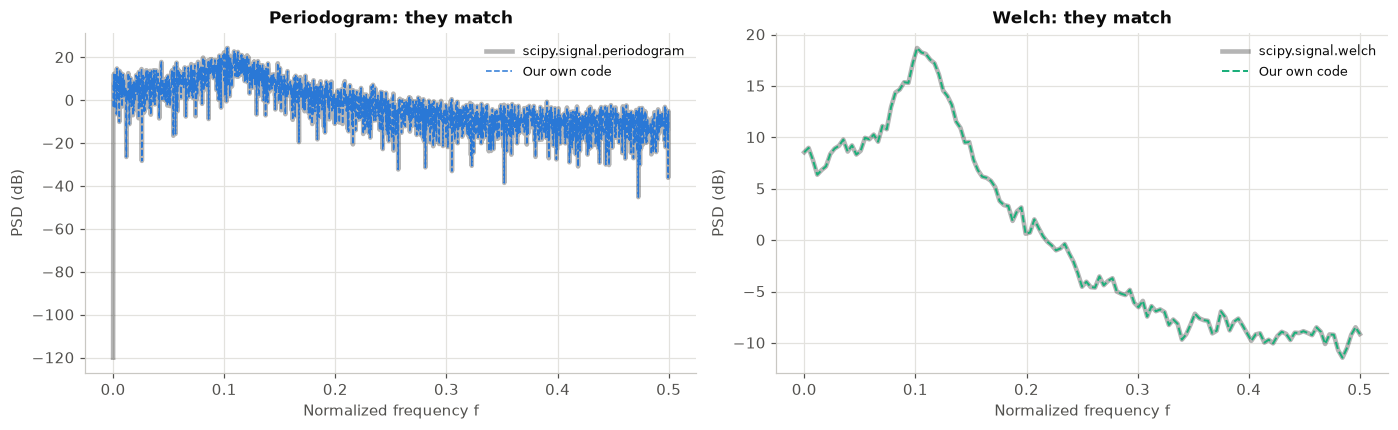

Largest relative difference, periodogram : 7.305e-02
Largest relative difference, welch       : 4.086e-15

→ our own code matches scipy
  (return_onesided=False compares the two-sided PSD directly;
   the default return_onesided=True multiplies every bin except DC and Nyquist by 2)


In [26]:
# ---- Check our own code against scipy ----
fs_v  = 1.0
N_v   = 4096
L_v   = 256
x_v   = sig.lfilter([1.0], a_cmp, rng.standard_normal(N_v+1000))[1000:]

# --- periodogram ---
f_sp, P_sp = sig.periodogram(x_v, fs=fs_v, window="boxcar",
                             nfft=N_v, return_onesided=False, scaling="density")
half   = N_v//2 + 1
P_mine = np.abs(np.fft.rfft(x_v, N_v))**2 / N_v

# --- welch ---
f_sw, P_sw = sig.welch(x_v, fs=fs_v, window="hann", nperseg=L_v,
                       noverlap=L_v//2, nfft=L_v, return_onesided=False,
                       scaling="density", detrend=False)
_, P_mw, _ = welch_psd(x_v, L_v, 0.5, "hann", NFFT=L_v)
halfw = L_v//2 + 1

fig, ax = plt.subplots(1, 2, figsize=(12.8, 4.0))

fp = np.fft.rfftfreq(N_v)
ax[0].plot(fp, 10*np.log10(P_sp[:half]+1e-12), color=C_TRUE, lw=3.0, alpha=0.30,
           label="scipy.signal.periodogram")
ax[0].plot(fp, 10*np.log10(P_mine+1e-12), "--", color=C_PER, lw=1.0,
           label="Our own code")
ax[0].set_xlabel("Normalized frequency f"); ax[0].set_ylabel("PSD (dB)")
ax[0].set_title("Periodogram: they match")
ax[0].legend(loc="upper right", fontsize=8.5)

fw = np.fft.rfftfreq(L_v)
ax[1].plot(fw, 10*np.log10(P_sw[:halfw]+1e-12), color=C_TRUE, lw=3.0, alpha=0.30,
           label="scipy.signal.welch")
ax[1].plot(fw, 10*np.log10(P_mw+1e-12), "--", color=C_WEL, lw=1.3,
           label="Our own code")
ax[1].set_xlabel("Normalized frequency f"); ax[1].set_ylabel("PSD (dB)")
ax[1].set_title("Welch: they match")
ax[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout(); plt.show()

e1 = np.max(np.abs(P_sp[:half] - P_mine)) / P_mine.mean()
e2 = np.max(np.abs(P_sw[:halfw] - P_mw)) / P_mw.mean()
print(f"Largest relative difference, periodogram : {e1:.3e}")
print(f"Largest relative difference, welch       : {e2:.3e}")
print("\n→ our own code matches scipy")
print("  (return_onesided=False compares the two-sided PSD directly;")
print("   the default return_onesided=True multiplies every bin except DC and Nyquist by 2)"
      )

### Key parameters of `scipy.signal.welch`

```python
f, Pxx = scipy.signal.welch(
    x,
    fs=1.0,             # sampling frequency, so f comes out in Hz
    window='hann',      # window; 'boxcar' + noverlap=0 gives Bartlett
    nperseg=256,        # ★ L, the main control (resolution vs variance)
    noverlap=None,      # default nperseg // 2 (50% overlap)
    nfft=None,          # zero-padding (a smoother curve, not more resolution)
    detrend='constant', # ★ removes each segment's mean, so DC does not leak over real peaks
    scaling='density',  # 'density' = PSD (V²/Hz) | 'spectrum' = power (V²)
    average='mean',     # 'median' copes better with spikes
)
```

The two parameters people get wrong most often:

- `detrend='constant'` is the default, and a good one. If you turn it off, any leftover DC leaks
  across the spectrum.
- `scaling`: to read the amplitude of a sine, use `'spectrum'`, not `'density'`.

### How to get each method

| Method | Call |
|---|---|
| Periodogram | `sig.periodogram(x, window='boxcar')` |
| Bartlett | `sig.welch(x, window='boxcar', nperseg=L, noverlap=0)` |
| Welch (standard) | `sig.welch(x, window='hann', nperseg=L)` |
| Welch, robust to spikes | `sig.welch(x, nperseg=L, average='median')` |

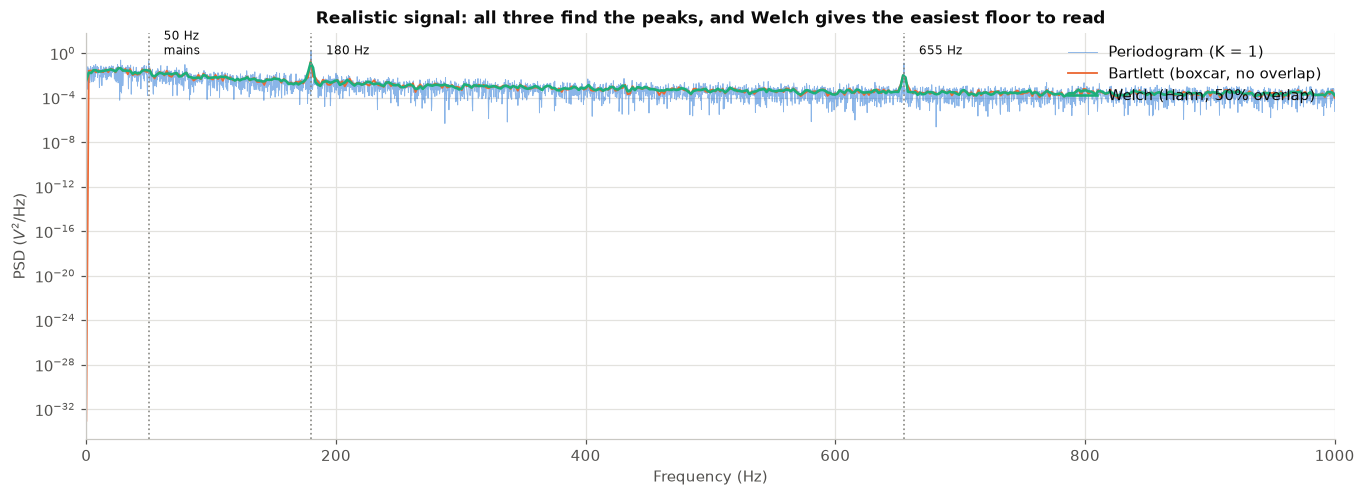

Total power (Parseval's theorem); every method should come out close:
  time domain  : 3.3012
  Periodogram  : 3.2907
  Bartlett     : 3.2280
  Welch        : 3.1684


In [27]:
# ---- All three methods with scipy alone, on a realistic signal ----
fs_r  = 2000.0                       # 2 kHz
T     = 4.0
n_r   = int(fs_r*T)
t_r   = np.arange(n_r)/fs_r

# Signal: two carriers + coloured noise + 50 Hz mains hum leaking in
x_r = (0.9*np.sin(2*np.pi*180*t_r)
       + 0.25*np.sin(2*np.pi*655*t_r)
       + 0.35*np.sin(2*np.pi*50*t_r)
       + sig.lfilter([1.0], [1.0, -0.85], 0.9*rng.standard_normal(n_r)))

f_p, P_p = sig.periodogram(x_r, fs=fs_r, window="boxcar")
f_b, P_b = sig.welch(x_r, fs=fs_r, window="boxcar", nperseg=1024, noverlap=0)
f_w, P_w = sig.welch(x_r, fs=fs_r, window="hann",   nperseg=1024)

fig, ax = plt.subplots(figsize=(12.5, 4.6))
ax.semilogy(f_p, P_p, color=C_PER, lw=0.6, alpha=0.55, label="Periodogram (K = 1)")
ax.semilogy(f_b, P_b, color=C_BAR, lw=1.2,             label="Bartlett (boxcar, no overlap)")
ax.semilogy(f_w, P_w, color=C_WEL, lw=1.7,             label="Welch (Hann, 50% overlap)")
for fmark, lab in [(50, "50 Hz\nmains"), (180, "180 Hz"), (655, "655 Hz")]:
    ax.axvline(fmark, color=C_MUTE, ls=":", lw=1.1)
    ax.text(fmark+12, P_p.max()*0.5, lab, fontsize=8, color=C_TRUE)
ax.set_xlim(0, fs_r/2); ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("PSD ($V^2$/Hz)")
ax.set_title("Realistic signal: all three find the peaks, and Welch gives the easiest floor to read")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

print("Total power (Parseval's theorem); every method should come out close:")
print(f"  time domain  : {np.mean(x_r**2):.4f}")
for nm, f_, P_ in [("Periodogram", f_p, P_p), ("Bartlett", f_b, P_b), ("Welch", f_w, P_w)]:
    print(f"  {nm:<13s}: {np.trapezoid(P_, f_):.4f}")

All methods give nearly the same total power (Parseval's theorem), which confirms the
normalization. What differs is how reliable each point is.

# Part 10. Summary

## 10.1 Comparison table

| | **Periodogram** | **Bartlett** | **Welch** |
|---|---|---|---|
| **Idea** | $\frac{1}{N}\|X(f)\|^2$ | $K$ non-overlapping segments, averaged | overlapping windowed segments, averaged |
| **Window** | rectangular | rectangular | any (usually Hann) |
| **Overlap** | none | 0% | usually 50% |
| **Variance** | $S^2(f)$ | $S^2(f)/K$ | $\approx \frac{S^2(f)}{K}(1+2\rho_1)$ |
| **Consistent?** | **no** | yes | yes |
| **Resolution** | $\sim 1/N$ (best) | $\sim 1/L$ | $\sim \text{ENBW}/L$ (slightly the worst) |
| **Leakage** | poor ($-13$ dB) | poor ($-13$ dB) | **good** ($-31$ dB with Hann) |
| **Use it for** | a baseline, or theory | teaching, simple cases | **the default for almost all real work** |

## 10.2 Formulas to remember

**The periodogram and its properties**

$$\hat{S}_{\text{per}}(f) = \frac{1}{N}\left|\sum_{n=0}^{N-1}x[n]e^{-j2\pi fn}\right|^{2}
= \sum_{m=-(N-1)}^{N-1}\hat{r}_{xx}[m]e^{-j2\pi fm}$$

$$E\{\hat{S}_{\text{per}}(f)\} = S(f)\circledast W_{B}(f),
\qquad W_{B}(f)=\frac{1}{N}\left(\frac{\sin \pi fN}{\sin \pi f}\right)^{2}$$

$$\operatorname{Var}\{\hat{S}_{\text{per}}(f)\} \approx S^{2}(f)
\quad\Longrightarrow\quad \text{a 100 percent error, whatever }N\text{ is}$$

**Welch**

$$\hat{S}_{W}(f)=\frac{1}{K}\sum_{i=0}^{K-1}\frac{1}{LU}
\left|\sum_{n=0}^{L-1}x[iD+n]w[n]e^{-j2\pi fn}\right|^{2},
\qquad U=\frac{1}{L}\sum_{n}w^{2}[n]$$

$$\operatorname{Var}\{\hat{S}_{W}\}=\frac{S^{2}}{K}
\left[1+2\sum_{j\ge1}\left(1-\frac{j}{K}\right)\rho[j]\right],
\qquad \rho[j]=\left[\frac{\sum_n w[n]w[n+jD]}{\sum_n w^{2}[n]}\right]^{2}$$

## 10.3 Practical guidelines

1. **Start with Welch, Hann and 50% overlap.** That is right for about 90% of jobs.
2. **Choose $L$ from the resolution you need.** To separate frequencies $\Delta f$ Hz apart, use
   $L \gtrsim 2 f_s/\Delta f$, with some margin for the ENBW of the window.
3. **Check $K$.** With $K < 8$ the result is still grassy: record more data or accept less
   resolution. There is no shortcut around this trade-off.
4. **A weak signal next to a strong one:** switch to Blackman–Harris.
5. **Spikes or outliers in the data:** use `average='median'`.
6. **Very high resolution from short data:** every periodogram-based method hits a wall here. Move
   to parametric methods (AR, Yule-Walker, Burg) or subspace methods (MUSIC, ESPRIT).

## 10.4 The notebook in one sentence

> **Spectral estimation trades resolution against variance, paid for out of a budget of data.**
>
> - The periodogram spends the whole budget on resolution, and its variance blows up.
> - Bartlett and Welch give up some resolution to buy lower variance.
> - $L$ sets the balance point, and Welch spends the budget best: overlap adds segments without
>   new data, and the window adds dynamic range.

### Further reading

- Welch, P.D. (1967). *The Use of Fast Fourier Transform for the Estimation of Power Spectra.*
  IEEE Trans. Audio Electroacoust. The original paper on Welch's method.
- Bartlett, M.S. (1948). *Smoothing Periodograms from Time Series with Continuous Spectra.* Nature.
- Harris, F.J. (1978). *On the Use of Windows for Harmonic Analysis with the DFT.*
  Proc. IEEE. Still the most complete reference on windows.
- Hayes, M.H. *Statistical Digital Signal Processing and Modeling.* Chapter 8 covers all of this.
- Stoica & Moses. *Spectral Analysis of Signals.* Continues into parametric methods.

**Where to go next:** Blackman–Tukey (windowing the ACF directly), Thomson's multitaper method with
several Slepian tapers at once, and parametric methods, which can beat the $1/N$ resolution limit
when the model is right.